LAB 06 - Attention Mechanism

In [18]:
from collections import Counter
from copy import deepcopy
from pathlib import Path
import random
import re
import sys
import time
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset

LAB_DIR = Path(r"D:\Study\Study_Class\Semester_7\NLP\Lab\lab06")
LAB06_DIR = OUTPUT_DIR = LAB_DIR
DATA_PATH = LAB_DIR.parent / "data" / "archive.zip"
RESULTS_PATH = OUTPUT_DIR / "results.csv"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

from attention_numpy import ScaledDotProductAttention

RANDOM_SEED = 2026
MAX_LENGTHS = [50, 100, 200]
MODEL_MAX_LENGTH = 100
MAX_VOCAB_SIZE = 20_000
EMBED_DIM = HIDDEN_DIM = 64
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 1e-3
GRADIENT_CLIP = 1.0
PAD_ID, UNK_ID = 0, 1
LABEL_TO_ID = {"negative": 0, "positive": 1}
ID_TO_LABEL = {value: key for key, value in LABEL_TO_ID.items()}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)


def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?")


def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())


def plot_token_attention(ax, tokens, weights, title, color="steelblue"):
    # Integer positions keep repeated tokens as separate bars.
    positions = np.arange(len(tokens))
    bars = ax.bar(positions, weights, color=color, edgecolor="white")
    ax.set_xticks(positions)
    ax.set_xticklabels(tokens, rotation=40, ha="right")
    ax.set(title=title, xlabel="Key token", ylabel="Attention weight")
    ax.set_ylim(0, max(float(np.max(weights)) * 1.3, 0.01))
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)


set_seed()
print("Dataset:", DATA_PATH)
print("Device:", DEVICE, "| PyTorch:", torch.__version__)
print("Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE)

Dataset: D:\Study\Study_Class\Semester_7\NLP\Lab\data\archive.zip
Device: cpu | PyTorch: 2.1.0+cpu
Epochs: 10 | Batch size: 128


Dataset preparation

,Dataset,Raw samples,Samples,Classes,Missing texts,Missing labels,Raw duplicate texts,Removed duplicate texts,Min length,Median length,Mean length,Max length,Length p90,Length p95
0,IMDb,50000,49578,2,0,0,418,422,6,173.0,231.21,2473,451.3,589.0


Removed normalized duplicate reviews: 422


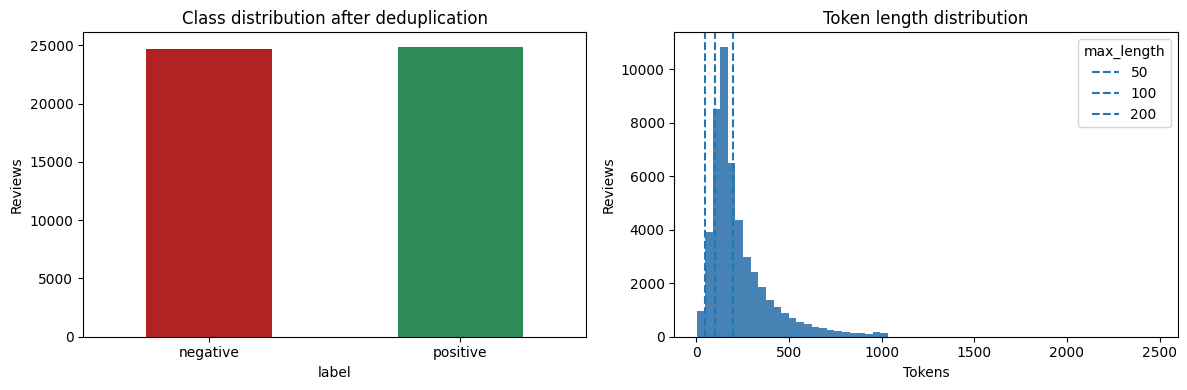

In [19]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(DATA_PATH)

with zipfile.ZipFile(DATA_PATH) as archive:
    with archive.open("IMDB Dataset.csv") as file:
        raw_df = pd.read_csv(file).rename(
            columns={"review": "text", "sentiment": "label"}
        )

raw_count = len(raw_df)
missing_texts = int(raw_df["text"].isna().sum())
missing_labels = int(raw_df["label"].isna().sum())
raw_duplicates = int(raw_df["text"].duplicated().sum())
df = raw_df.dropna(subset=["text", "label"]).copy()
df["text_clean"] = (
    df["text"].astype(str)
    .str.replace(r"<br\s*/?>", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True).str.strip()
)
df = df[df["text_clean"].ne("")].copy()
assert set(df["label"]).issubset(LABEL_TO_ID), "Unexpected labels"

# Same normalized text must never occur in different data splits.
df["text_key"] = df["text_clean"].str.lower()
conflicts = df.groupby("text_key")["label"].nunique()
if (conflicts > 1).any():
    raise ValueError("Duplicate reviews have conflicting labels; inspect first.")
clean_duplicates = int(df["text_key"].duplicated().sum())
df = df.drop_duplicates("text_key").reset_index(drop=True)
df["token_count"] = df["text_clean"].map(lambda text: len(tokenize(text)))

dataset_summary = pd.DataFrame([{
    "Dataset": "IMDb",
    "Raw samples": raw_count, "Samples": len(df),
    "Classes": df["label"].nunique(),
    "Missing texts": missing_texts, "Missing labels": missing_labels,
    "Raw duplicate texts": raw_duplicates,
    "Removed duplicate texts": clean_duplicates,
    "Min length": df["token_count"].min(),
    "Median length": df["token_count"].median(),
    "Mean length": df["token_count"].mean(),
    "Max length": df["token_count"].max(),
    "Length p90": df["token_count"].quantile(0.90),
    "Length p95": df["token_count"].quantile(0.95),
}])
display(dataset_summary.round(2))
print("Removed normalized duplicate reviews:", clean_duplicates)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["label"].value_counts().reindex(["negative", "positive"]).plot(
    kind="bar", ax=axes[0], color=["firebrick", "seagreen"], rot=0
)
axes[0].set_title("Class distribution after deduplication")
axes[0].set_ylabel("Reviews")
axes[1].hist(df["token_count"], bins=60, color="steelblue")
for length in MAX_LENGTHS:
    axes[1].axvline(length, linestyle="--", label=str(length))
axes[1].set(title="Token length distribution", xlabel="Tokens", ylabel="Reviews")
axes[1].legend(title="max_length")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "dataset_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

Nhận xét dữ liệu và ảnh hưởng của tiền xử lý

Dữ liệu gốc có 50.000 review, không thiếu văn bản hoặc nhãn. Có 418 review trùng nguyên bản; sau khi thay thẻ xuống dòng HTML bằng khoảng trắng, chuẩn hóa khoảng trắng và chuyển về chữ thường để tạo khóa so sánh, số review trùng cần loại là 422. Sau làm sạch còn 49.578 review. Số trùng tăng thêm 4 là do một số văn bản khác nhau ở hình thức trở thành giống nhau sau chuẩn hóa; không phải chương trình tự tạo thêm dữ liệu trùng.

Độ dài trung bình là 231,21 token, trung vị 173, ngắn nhất 6 và dài nhất 2.473. Phân vị 90% là 451,3 token và phân vị 95% là 589 token. Vì vậy, MODEL_MAX_LENGTH = 100 ngắn hơn cả trung vị của dữ liệu, nên truncation là một hạn chế quan trọng của thí nghiệm này. Kiểm tra trên test_predictions.csv cho thấy 8.664/9.916 mẫu test bị cắt, tương đương khoảng 87,37%. Các dự đoán chỉ dựa trên phần đầu được giữ, trong khi nhãn đánh giá thuộc toàn bộ review.

Việc loại review trùng trước khi chia tập giúp tránh cùng văn bản xuất hiện ở train và test. Vocabulary được xây dựng riêng từ train, không lấy từ validation hoặc test. Đây là điều kiện cần để các kết quả đánh giá phía dưới có ý nghĩa.

16-17. NumPy core and numerical stability

In [20]:
attention = ScaledDotProductAttention()

large_scores = np.array([1000.0, 1001.0, 1002.0])
stable_weights = attention.softmax(large_scores)
np.testing.assert_allclose(stable_weights, attention.softmax(large_scores - 1000.0))
np.testing.assert_allclose(stable_weights.sum(), 1.0)
assert np.isfinite(stable_weights).all()

display(pd.DataFrame({"Score": large_scores, "Softmax": stable_weights}))

# Check a complete attention computation with d_v different from d_k.
check_q = np.array([[1.0, 0.0], [0.0, 1.0]])
check_k = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
check_v = np.arange(9, dtype=np.float64).reshape(3, 3)
check_scores, check_weights, check_context = attention.scaled_dot_product_attention(
    check_q, check_k, check_v
)
np.testing.assert_allclose(check_scores, check_q @ check_k.T / np.sqrt(2))
np.testing.assert_allclose(check_weights.sum(axis=-1), 1.0)
np.testing.assert_allclose(check_context, check_weights @ check_v)
print("Output shapes:", check_scores.shape, check_weights.shape, check_context.shape)

,Score,Softmax
0,1000.0,0.090031
1,1001.0,0.244728
2,1002.0,0.665241


Output shapes: (2, 3) (2, 3) (2, 3)


Kiểm tra đáp án phần core và trả lời câu hỏi numerical stability

Với scores [1000, 1001, 1002], output softmax là [0,090031; 0,244728; 0,665241]. Các phần tử hữu hạn và có tổng bằng 1. Phần tử cuối nhận weight lớn nhất, đúng với thứ tự của score. Khi trừ giá trị lớn nhất 1002, đầu vào của hàm mũ trở thành [-2, -1, 0], tránh phải tính exp(1002), vốn vượt miền biểu diễn của float64.

Tại sao trừ max(x) không đổi kết quả? Đặt m = max(x). Khi đó exp(x_i - m) = exp(x_i) / exp(m). Tất cả số hạng ở tử và mẫu cùng chia cho exp(m), nên hệ số chung triệt tiêu. Đây là cùng một phân phối softmax về mặt toán học, nhưng được tính ổn định hơn về số.

Trong kiểm tra attention đầy đủ, Q có shape (2, 2), K có shape (3, 2), V có shape (3, 3). Vì vậy, d_k = 2; scores và attention_weights đều có shape (2, 3), còn context có shape (2, 3), đúng với output đã in. Trường hợp này cũng kiểm tra rằng chiều value d_v không bắt buộc bằng chiều key d_k. Các phép assert đã xác nhận scores = QK.T / sqrt(d_k), tổng weight của từng hàng bằng 1 và context = attention_weights @ V.

14-15. Scaling and temperature

,Raw score,Scaled score,Unscaled weight,Scaled weight
0,4.0,2.0,0.866813,0.665241
1,2.0,1.0,0.117310,0.244728
2,0.0,0.0,0.015876,0.090031


,Temperature,Max weight,Entropy (nats)
0,0.5,0.866813,0.441057
1,1.0,0.665241,0.832396
2,2.0,0.506480,1.020191


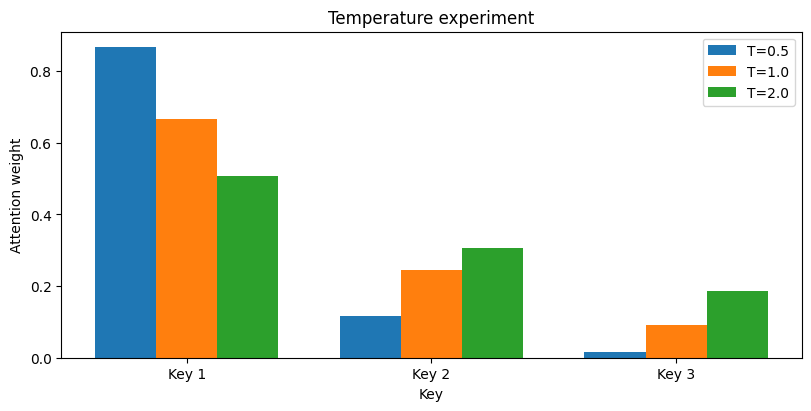

In [21]:
raw_scores = np.array([4.0, 2.0, 0.0])
d_k = 4
scaled_scores = raw_scores / np.sqrt(d_k)

scaling_table = pd.DataFrame({
    "Raw score": raw_scores,
    "Scaled score": scaled_scores,
    "Unscaled weight": attention.softmax(raw_scores),
    "Scaled weight": attention.softmax(scaled_scores),
})
display(scaling_table.round(6))

temperatures = [0.5, 1.0, 2.0]
temperature_distributions = {
    temperature: attention.softmax(scaled_scores / temperature)
    for temperature in temperatures
}
temperature_results = pd.DataFrame([
    {
        "Temperature": temperature,
        "Max weight": weights.max(),
        "Entropy (nats)": -np.sum(weights * np.log(weights.clip(min=1e-12))),
    }
    for temperature, weights in temperature_distributions.items()
])
display(temperature_results.round(6))
temperature_results.to_csv(OUTPUT_DIR / "temperature_results.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
positions = np.arange(len(scaled_scores))
for index, (temperature, weights) in enumerate(temperature_distributions.items()):
    ax.bar(positions + (index - 1) * 0.25, weights, width=0.25, label=f"T={temperature}")
ax.set_xticks(positions)
ax.set_xticklabels(["Key 1", "Key 2", "Key 3"])
ax.set(title="Temperature experiment", xlabel="Key", ylabel="Attention weight")
ax.legend()
fig.savefig(OUTPUT_DIR / "scaling_temperature.png", dpi=160, bbox_inches="tight")
plt.show()

Nhận xét scaling và trả lời câu hỏi về độ tập trung của softmax

Với d_k = 4, sqrt(d_k) = 2 nên raw scores [4, 2, 0] trở thành scaled scores [2, 1, 0]. Khi chưa scaling, weights là [0,866813; 0,117310; 0,015876]. Sau scaling, weights là [0,665241; 0,244728; 0,090031]. Weight lớn nhất giảm từ 86,68% xuống 66,52%, còn hai key còn lại đều tăng weight. Thứ tự ưu tiên không đổi nhưng phân phối bớt tập trung.

Chia cho sqrt(d_k) kiểm soát độ lớn của dot product khi chiều key tăng. Trong ví dụ d_k = 4, phép chia làm chênh lệch giữa các scores nhỏ lại, nên softmax bớt tiến gần phân phối chỉ tập trung vào một key. Đây là ảnh hưởng của scaling quan sát trực tiếp từ bảng, không phải thay đổi key được ưu tiên nhất.

Thí nghiệm temperature giữ nguyên scaled scores [2, 1, 0]:

- T = 0,5: max weight = 0,866813; entropy = 0,441057 nat. Phân phối tập trung nhất trong ba trường hợp.
- T = 1,0: max weight = 0,665241; entropy = 0,832396 nat. Đây là softmax thông thường của scaled scores.
- T = 2,0: max weight = 0,506480; entropy = 1,020191 nat. Phân phối phẳng hơn và dành nhiều weight hơn cho các key không đứng đầu.

Entropy của phân phối đều trên ba key là ln(3), khoảng 1,098612 nat. Kết quả T = 2,0 gần mức này hơn T = 0,5, nhưng chưa hoàn toàn đều. Khi T giảm, chênh lệch scores/T tăng nên phân phối tập trung; khi T tăng thì ngược lại. T = 0,5 ở đây cho cùng phân phối với raw scores vì [2, 1, 0] / 0,5 = [4, 2, 0].

18. Experiment 1 - Attention distribution

In [22]:
sentence = (
    "The movie was surprisingly good despite "
    "a very slow beginning."
)
tokens = sentence.rstrip(".").split()

# Hand-designed toy features (not learned embeddings): sentiment, topic, speed, modifier.
# This query is designed to focus on positive sentiment.
Q = np.array([[1.0, 0.0, 0.0, 0.0]])

# Each row of K corresponds to one token.
K = np.array([
    [0.0, 0.0, 0.0, 0.2],   # The
    [0.0, 1.0, 0.0, 0.0],   # movie
    [0.0, 0.0, 0.0, 0.0],   # was
    [0.8, 0.0, 0.0, 1.0],   # surprisingly
    [2.0, 0.0, 0.0, 0.0],   # good
    [0.0, 0.0, 0.0, 0.0],   # despite
    [0.0, 0.0, 0.0, 0.0],   # a
    [0.0, 0.0, 0.5, 1.0],   # very
    [-1.0, 0.0, 1.5, 0.0],  # slow
    [-0.5, 0.0, 1.0, 0.0],  # beginning
], dtype=np.float64)

# For this experiment, use the same toy representation as V.
V = K.copy()

assert len(tokens) == K.shape[0]

In [23]:
attention = ScaledDotProductAttention()
scores, attention_weights, context = (
    attention.scaled_dot_product_attention(Q, K, V)
)

scores = scores.squeeze(0)
attention_weights = attention_weights.squeeze(0)

attention_table = pd.DataFrame({
    "Token": tokens,
    "Score": scores,
    "Attention": attention_weights,
})

display(
    attention_table.style.format({
        "Score": "{:.4f}",
        "Attention": "{:.4f}",
    })
)

assert np.isclose(attention_weights.sum(), 1.0)
print("Attention sum:", attention_weights.sum())
print("Highest-attention token:", tokens[int(np.argmax(attention_weights))])

,Token,Score,Attention
0,The,0.0000,0.0862
1,movie,0.0000,0.0862
2,was,0.0000,0.0862
3,surprisingly,0.4000,0.1287
4,good,1.0000,0.2344
5,despite,0.0000,0.0862
6,a,0.0000,0.0862
7,very,0.0000,0.0862
8,slow,-0.5000,0.0523
9,beginning,-0.2500,0.0672


Attention sum: 1.0
Highest-attention token: good


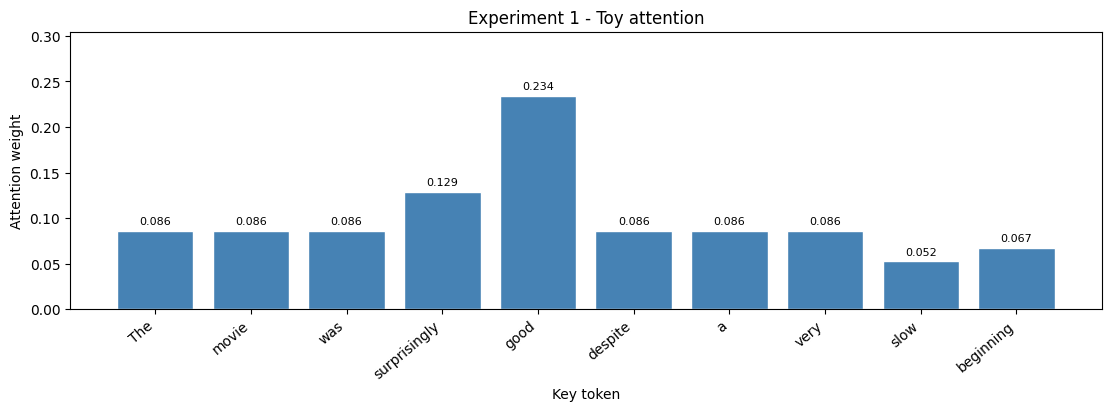

In [24]:
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
plot_token_attention(ax, tokens, attention_weights, "Experiment 1 - Toy attention")
fig.savefig(OUTPUT_DIR / "attention_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

Nhận xét Experiment 1: model đang phân phối trọng số như thế nào?

Câu có 10 token, query có shape (1, 4), nên attention là một phân phối trên 10 key. Với query [1, 0, 0, 0], score của mỗi token bằng đặc trưng thứ nhất trong K chia cho sqrt(4) = 2.

Token "good" có score 1,0 và attention 0,234427, cao nhất câu; "surprisingly" có score 0,4 và attention 0,128656. "slow" có score -0,5 và attention 0,052308, thấp nhất; "beginning" có score -0,25 và attention 0,067164. Sáu token "The", "movie", "was", "despite", "a", "very" cùng score 0 nên cùng attention khoảng 0,086241.

Tổng attention bằng 1 theo output. Weight lớn nhất chỉ khoảng 23,44%, nên attention chưa tập trung gần như toàn bộ vào "good"; các token còn lại vẫn góp vào context. Score âm cũng không có nghĩa weight bằng 0: "slow" vẫn nhận khoảng 5,23%.

Vì V = K trong ví dụ, phép tổng có trọng số cho context xấp xỉ [0,485889; 0,086241; 0,188746; 0,232145]. Đây là một vector tổng hợp từ cả 10 value. Các đặc trưng và query đã được gán tay, nên ưu tiên "good" là kết quả của thiết kế vector, chưa phải bằng chứng một model được huấn luyện đã học sentiment của câu.

19. Experiment 2 - Query changes

In [25]:
# Reuse tokens, K and V from Experiment 1.
queries = {
    "Query A - Sentiment": np.array([[1.0, 0.0, 0.0, 0.0]]),
    "Query B - Topic": np.array([[0.0, 1.0, 0.0, 0.0]]),
}

query_results = {}
for query_name, query in queries.items():
    query_scores, query_weights, query_context = (
        attention.scaled_dot_product_attention(query, K, V)
    )

    query_results[query_name] = {
        "scores": query_scores.squeeze(0),
        "attention": query_weights.squeeze(0),
        "context": query_context.squeeze(0),
    }

comparison_table = pd.DataFrame({
    "Token": tokens,
    "Score - Sentiment": query_results["Query A - Sentiment"]["scores"],
    "Attention - Sentiment": query_results["Query A - Sentiment"]["attention"],
    "Score - Topic": query_results["Query B - Topic"]["scores"],
    "Attention - Topic": query_results["Query B - Topic"]["attention"],
})

display(
    comparison_table.style.format({
        "Score - Sentiment": "{:.4f}",
        "Attention - Sentiment": "{:.4f}",
        "Score - Topic": "{:.4f}",
        "Attention - Topic": "{:.4f}",
    })
)

for result in query_results.values():
    assert np.isclose(result["attention"].sum(), 1.0)

sentiment_weights = query_results["Query A - Sentiment"]["attention"]
topic_weights = query_results["Query B - Topic"]["attention"]
assert not np.allclose(sentiment_weights, topic_weights)

print("Query A highest-attention token:", tokens[int(np.argmax(sentiment_weights))])
print("Query B highest-attention token:", tokens[int(np.argmax(topic_weights))])
print("Distributions are different:", not np.allclose(sentiment_weights, topic_weights))

,Token,Score - Sentiment,Attention - Sentiment,Score - Topic,Attention - Topic
0,The,0.0000,0.0862,0.0000,0.0939
1,movie,0.0000,0.0862,0.5000,0.1548
2,was,0.0000,0.0862,0.0000,0.0939
3,surprisingly,0.4000,0.1287,0.0000,0.0939
4,good,1.0000,0.2344,0.0000,0.0939
5,despite,0.0000,0.0862,0.0000,0.0939
6,a,0.0000,0.0862,0.0000,0.0939
7,very,0.0000,0.0862,0.0000,0.0939
8,slow,-0.5000,0.0523,0.0000,0.0939
9,beginning,-0.2500,0.0672,0.0000,0.0939


Query A highest-attention token: good
Query B highest-attention token: movie
Distributions are different: True


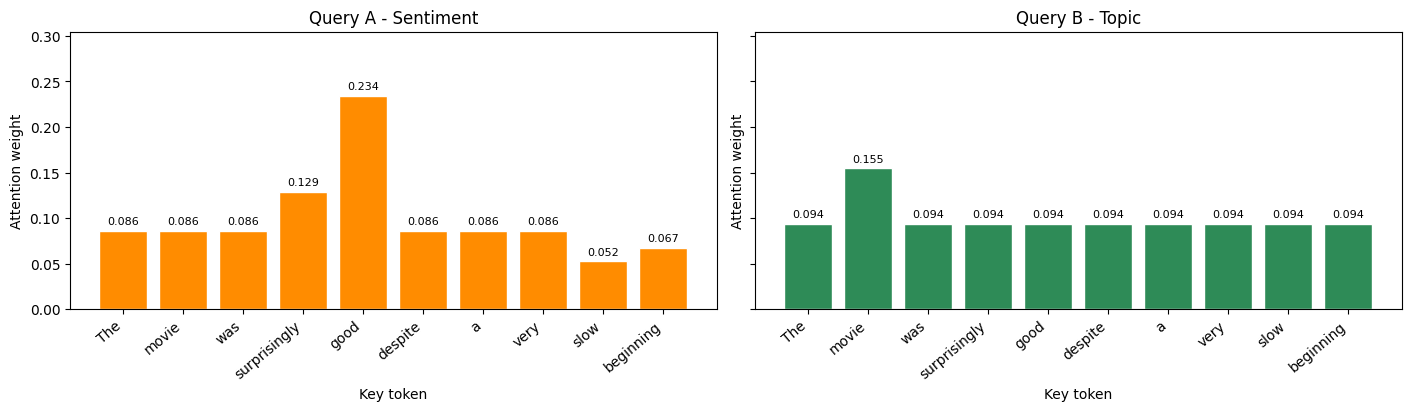

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True, constrained_layout=True)
max_weight = max(result["attention"].max() for result in query_results.values())
for ax, (name, result), color in zip(axes, query_results.items(), ["darkorange", "seagreen"]):
    plot_token_attention(ax, tokens, result["attention"], name, color=color)
    ax.set_ylim(0, max_weight * 1.3)
fig.savefig(OUTPUT_DIR / "attention_query_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

Nhận xét Experiment 2: attention distribution có thay đổi khi query thay đổi không?

Có. Sequence, K, V, cách scaling và softmax được giữ nguyên; chỉ đổi Q. Với Query A = [1, 0, 0, 0], "good" đứng đầu với weight 0,234427, sau đó là "surprisingly" với 0,128656. Đây là query chọn trục sentiment đã định nghĩa trong toy vectors.

Với Query B = [0, 1, 0, 0], "movie" có score 0,5 và weight 0,154828, cao nhất. Chín token còn lại cùng score 0 và weight 0,093908. Riêng "good" giảm từ 0,234427 xuống 0,093908, còn "movie" tăng từ 0,086241 lên 0,154828. Output kiểm tra hai phân phối khác nhau trả về True; tổng của từng phân phối vẫn bằng 1.

Context cũng thay đổi: Query A cho [0,485889; 0,086241; 0,188746; 0,232145], còn Query B cho [0,122080; 0,154828; 0,281724; 0,206598]. Như vậy cùng một tập value nhưng cách phối trộn khác khi mục tiêu truy vấn đổi.

Trong ví dụ, "good" không phải token luôn nhận weight cao nhất cho mọi query; khi chuyển sang trục topic, "movie" đứng đầu. Vì các trục này được gán tay, thí nghiệm minh họa sự phụ thuộc vào query và không tự chứng minh model đã học được hai khái niệm sentiment/topic từ dữ liệu.

20-22. NumPy self-attention: Q = XW_Q, K = XW_K, V = XW_V

Q


,0,1
I,1.0,0.0
like,0.0,1.0
cats,1.0,1.0


K


,0,1
I,0.5,1.0
like,1.0,0.5
cats,1.5,1.5


V


...

,0,1,2
I,0.3536,0.7071,1.0607
like,0.7071,0.3536,1.0607
cats,1.0607,1.0607,2.1213


Attention


,0,1,2
I,0.2246,0.3199,0.4555
like,0.3199,0.2246,0.4555
cats,0.2046,0.2046,0.5909


Context


,0,1
I,1.4555,-0.0953
like,1.4555,0.0953
cats,1.5909,0.0000


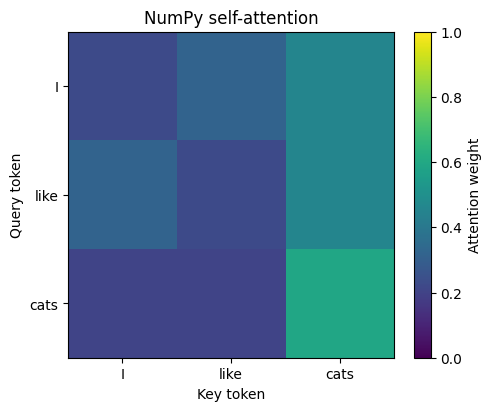

In [27]:
# Illustrative matrices; use instructor-provided values if available.
self_tokens = ["I", "like", "cats"]
self_x = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
self_wq = np.eye(2)
self_wk = np.array([[0.5, 1.0], [1.0, 0.5]])
self_wv = np.array([[1.0, 1.0], [1.0, -1.0]])
self_q, self_k, self_v = self_x @ self_wq, self_x @ self_wk, self_x @ self_wv
self_scores, self_weights, self_context = attention.scaled_dot_product_attention(
    self_q, self_k, self_v
)
for name, matrix in {
    "Q": self_q, "K": self_k, "V": self_v, "QK.T": self_q @ self_k.T,
    "Scaled scores": self_scores, "Attention": self_weights, "Context": self_context,
}.items():
    print(name)
    display(pd.DataFrame(matrix, index=self_tokens).round(4))

fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
image = ax.imshow(self_weights, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(3), labels=self_tokens)
ax.set_yticks(range(3), labels=self_tokens)
ax.set(xlabel="Key token", ylabel="Query token", title="NumPy self-attention")
fig.colorbar(image, ax=ax, label="Attention weight")
fig.savefig(OUTPUT_DIR / "self_attention_toy.png", dpi=160, bbox_inches="tight")
plt.show()

Kiểm tra kết quả self-attention NumPy và cách đọc attention matrix

X có shape (3, 2); ba phép chiếu tạo Q, K, V cùng xuất phát từ sequence ["I", "like", "cats"]. W_Q là ma trận đơn vị nên Q = X, còn K và V khác X do W_K và W_V khác nhau. Đây là self-attention dù các phép chiếu không cho cùng vector.

Output QK.T là [[0,5; 1,0; 1,5], [1,0; 0,5; 1,5], [1,5; 1,5; 3,0]]. Chia cho sqrt(2) và softmax theo từng hàng cho attention xấp xỉ [[0,2246; 0,3199; 0,4555], [0,3199; 0,2246; 0,4555], [0,2046; 0,2046; 0,5909]].

Hàng là query token, cột là key token. Vì vậy, hàng "I" cho biết "I" đang nhận thông tin từ các value của "I", "like", "cats" với weights tương ứng 0,2246; 0,3199; 0,4555. Cả ba query đều dành weight lớn nhất cho "cats" trong ví dụ này. Tổng từng hàng trước khi làm tròn bằng 1; sai lệch 0,0001 khi cộng các số đã làm tròn chỉ là do hiển thị.

Context của "I" là [1,4555; -0,0953], của "like" là [1,4555; 0,0953], của "cats" là [1,5909; 0]. Mỗi token được biểu diễn lại bằng tổ hợp của nhiều value thay vì chỉ giữ embedding ban đầu. Các X/W ở đây là ma trận minh họa được nêu trong code; kết quả xác nhận phép tính của bộ ma trận này, không đại diện cho embedding ngôn ngữ đã học.

23. Experiment 3 - Attention visualization

In [28]:
sentence_tokens = {
    "Cat sentence": [
        "The", "cat", "that", "I",
        "adopted", "yesterday", "is", "sleeping",
    ],
    "Book sentence": [
        "The", "book", "that", "I",
        "bought", "yesterday", "was", "expensive",
    ],
}

# Manually designed toy vectors; these are not trained linguistic representations.
toy_vectors = {
    "the": [0.0, 0.0, 0.0, 0.0],
    "cat": [1.0, 0.0, 0.0, 0.5],
    "that": [0.0, 0.0, 0.0, 0.0],
    "i": [0.2, 0.2, 0.0, 0.0],
    "adopted": [0.8, 1.0, 0.0, 0.0],
    "yesterday": [0.0, 0.0, 1.0, 0.0],
    "is": [0.0, 0.0, 0.0, 0.0],
    "sleeping": [0.8, 0.8, 0.0, 1.0],
    "book": [1.0, 0.0, 0.0, 0.5],
    "bought": [0.8, 1.0, 0.0, 0.0],
    "was": [0.0, 0.0, 0.0, 0.0],
    "expensive": [0.8, 0.0, 0.0, 1.0],
}

attention_exp3 = ScaledDotProductAttention()
attention_matrices = {}

for sentence_name, tokens_for_sentence in sentence_tokens.items():
    X = np.array(
        [toy_vectors[token.lower()] for token in tokens_for_sentence],
        dtype=np.float64,
    )

    # Identity projections are a special case: W_Q = W_K = W_V = I.
    scores, weights, context = (
        attention_exp3.scaled_dot_product_attention(X, X, X)
    )

    attention_matrices[sentence_name] = {
        "tokens": tokens_for_sentence,
        "scores": scores,
        "weights": weights,
        "context": context,
    }

    assert weights.shape == (len(tokens_for_sentence), len(tokens_for_sentence))
    assert np.allclose(weights.sum(axis=1), 1.0)

print("Attention matrices computed:")
for sentence_name, result in attention_matrices.items():
    print(f"{sentence_name}: {result['weights'].shape}")

Attention matrices computed:
Cat sentence: (8, 8)
Book sentence: (8, 8)


In [29]:
# Inspect the top-3 attended tokens for the requested query tokens.
target_tokens = ["cat", "adopted", "sleeping"]
cat_result = attention_matrices["Cat sentence"]
cat_tokens = [token.lower() for token in cat_result["tokens"]]
cat_weights = cat_result["weights"]

focus_rows = []
for query_token in target_tokens:
    query_index = cat_tokens.index(query_token)
    query_weights = cat_weights[query_index]
    top_indices = np.argsort(query_weights)[::-1][:3]

    for rank, key_index in enumerate(top_indices, start=1):
        focus_rows.append({
            "Query token": query_token,
            "Rank": rank,
            "Attended token": cat_result["tokens"][key_index],
            "Attention": query_weights[key_index],
        })

focus_table = pd.DataFrame(focus_rows)
display(
    focus_table.style.format({"Attention": "{:.4f}"})
)

,Query token,Rank,Attended token,Attention
0,cat,1,sleeping,0.1845
1,cat,2,cat,0.1800
2,cat,3,adopted,0.1437
3,adopted,1,adopted,0.2061
4,adopted,2,sleeping,0.1865
5,adopted,3,cat,0.1354
6,sleeping,1,sleeping,0.2548
7,sleeping,2,adopted,0.1674
8,sleeping,3,cat,0.1561


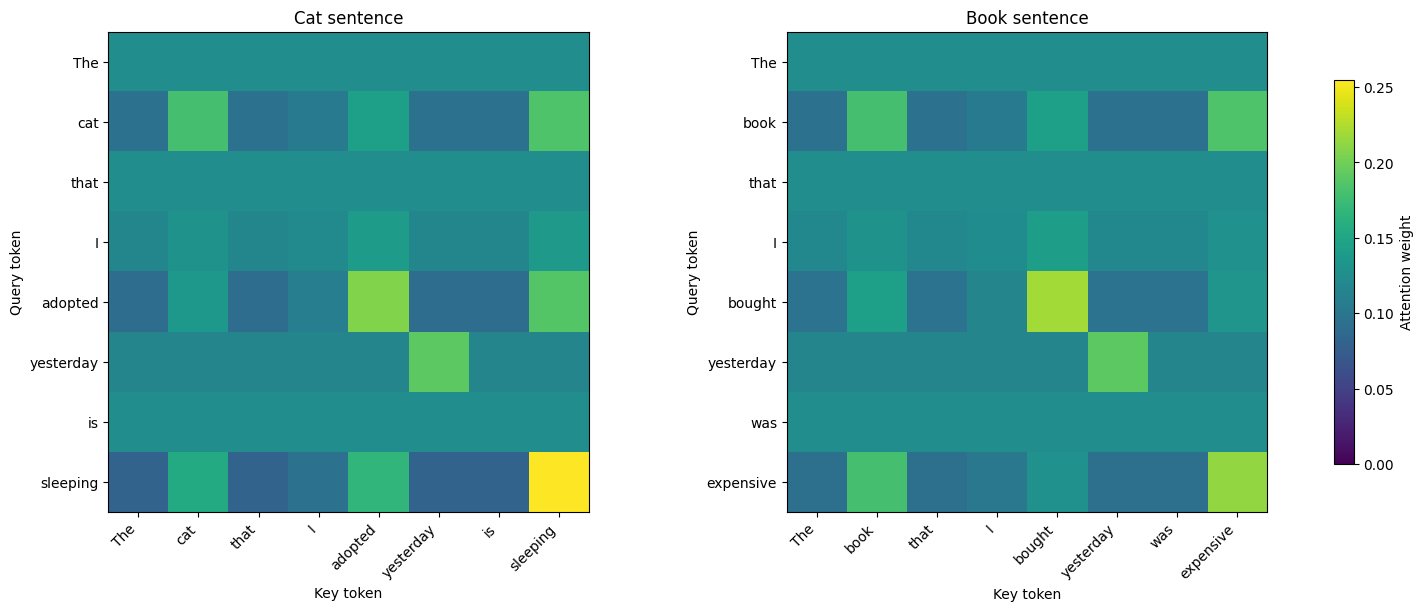

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
max_weight = max(result["weights"].max() for result in attention_matrices.values())
for ax, (name, result) in zip(axes, attention_matrices.items()):
    image = ax.imshow(result["weights"], cmap="viridis", vmin=0, vmax=max_weight)
    positions = np.arange(len(result["tokens"]))
    ax.set_xticks(positions, labels=result["tokens"], rotation=45, ha="right")
    ax.set_yticks(positions, labels=result["tokens"])
    ax.set(title=name, xlabel="Key token", ylabel="Query token")
fig.colorbar(image, ax=axes, label="Attention weight", shrink=0.8)
fig.savefig(OUTPUT_DIR / "attention_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

Nhận xét Experiment 3 và các token được yêu cầu

Mỗi câu sau tokenization có 8 token nên attention matrix có shape (8, 8), đúng với output. Mỗi hàng là một phân phối có tổng bằng 1; màu sáng hơn nghĩa là weight cao hơn trên cùng thang màu. Self-attention cho phép một token attend tới chính nó, nên cần giữ cột đường chéo khi đọc top-3.

Trong câu "The cat that I adopted yesterday is sleeping.", bảng top-3 cho thấy:

- Query "cat": "sleeping" nhận 0,184528, "cat" nhận 0,179972, "adopted" nhận 0,143710. Weight lớn nhất hướng sang "sleeping", nhỉnh hơn self-attention của "cat".
- Query "adopted": "adopted" nhận 0,206147, "sleeping" nhận 0,186530, "cat" nhận 0,135448. Token này ưu tiên chính nó, sau đó tới "sleeping" và "cat".
- Query "sleeping": "sleeping" nhận 0,254825, "adopted" nhận 0,167432, "cat" nhận 0,156113. Weight tự chú ý chiếm khoảng 25,48%, nhưng phần lớn tổng weight vẫn phân bố sang các token khác.

Các hàng "The", "that", "is" đều có weight 0,125 ở cả tám cột vì vector query bằng 0, làm mọi dot product của hàng bằng nhau. Đây là hệ quả của cách gán toy vector, không phải kết luận các từ chức năng không có vai trò ngôn ngữ.

Ở câu về book, hàng "book" dành khoảng 0,184528 cho "expensive" và 0,179972 cho chính nó; "bought" dành 0,219655 cho chính nó. Hai heatmap có nhiều phần giống nhau vì code chủ động gán vector "book" giống "cat", "bought" giống "adopted", và dùng phép chiếu đơn vị. Sự giống nhau này xuất phát từ dữ liệu giả lập.

Phân biệt attention pattern và linguistic explanation: heatmap xác nhận những phân phối và cặp weight nói trên. Nó không xác nhận model đã học quan hệ chủ ngữ-vị ngữ hay reasoning. Ví dụ, "cat" attend tới "sleeping" 0,184528 trong khi chiều ngược lại chỉ là 0,156113; attention không nhất thiết đối xứng dù Q = K, vì mỗi hàng softmax có mẫu số riêng. Muốn giải thích ngôn ngữ cần thêm bằng chứng từ model được huấn luyện và các kiểm tra hành vi, thay vì chỉ dựa vào vị trí ô sáng.

24. Experiment 4 - LSTM context vs Attention context

In [31]:
EXP4_MAX_LENGTH = MODEL_MAX_LENGTH
model_df = df[["text_clean", "text_key", "token_count", "label"]].reset_index(
    names="sample_id"
)
development_df, test_df = train_test_split(
    model_df, test_size=0.2, stratify=model_df["label"], random_state=RANDOM_SEED
)
train_df, val_df = train_test_split(
    development_df, test_size=0.2,
    stratify=development_df["label"], random_state=RANDOM_SEED,
)
train_df, val_df, test_df = [
    frame.reset_index(drop=True) for frame in (train_df, val_df, test_df)
]
assert set(train_df["text_key"]).isdisjoint(val_df["text_key"])
assert set(train_df["text_key"]).isdisjoint(test_df["text_key"])
assert set(val_df["text_key"]).isdisjoint(test_df["text_key"])

token_counter = Counter(token for text in train_df["text_clean"] for token in tokenize(text))
vocab = {"<pad>": PAD_ID, "<unk>": UNK_ID}
for token, _ in token_counter.most_common(MAX_VOCAB_SIZE - len(vocab)):
    vocab[token] = len(vocab)


def encode_text(text):
    return [vocab.get(token, UNK_ID) for token in tokenize(text)[:EXP4_MAX_LENGTH]] or [UNK_ID]


class SentimentDataset(Dataset):
    def __init__(self, frame):
        self.sequences = [torch.tensor(encode_text(text)) for text in frame["text_clean"]]
        self.labels = frame["label"].map(LABEL_TO_ID).to_numpy()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.sequences[index], int(self.labels[index])


def collate_batch(batch):
    sequences, labels = zip(*batch)
    sequences = [torch.as_tensor(sequence, dtype=torch.long) for sequence in sequences]
    lengths = torch.tensor([len(sequence) for sequence in sequences], dtype=torch.long)
    input_ids = pad_sequence(sequences, batch_first=True, padding_value=PAD_ID)
    return input_ids, lengths, torch.tensor(labels, dtype=torch.long)


train_dataset, val_dataset, test_dataset = [
    SentimentDataset(frame) for frame in (train_df, val_df, test_df)
]
loader_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    collate_fn=collate_batch, generator=loader_generator,
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, collate_fn=collate_batch)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, collate_fn=collate_batch)
display(pd.DataFrame([
    {"Split": name, "Samples": len(frame), **frame["label"].value_counts().to_dict()}
    for name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]
]))
print("Vocabulary:", len(vocab), "| Maximum length:", EXP4_MAX_LENGTH)

,Split,Samples,positive,negative
0,Train,31729,15924,15805
1,Validation,7933,3981,3952
2,Test,9916,4977,4939


Vocabulary: 20000 | Maximum length: 100


Thiết lập so sánh hai classifier

Train có 31.729 mẫu (15.924 positive, 15.805 negative); validation có 7.933 mẫu (3.981 positive, 3.952 negative); test có 9.916 mẫu (4.977 positive, 4.939 negative). Tổng đúng 49.578 mẫu sau làm sạch. Các lớp gần cân bằng; accuracy toàn tập và F1 của lớp positive được báo cáo cùng nhau.

Hai model cùng dùng vocabulary 20.000 token chỉ học từ train, embedding 64 chiều, representation 64 chiều, max length 100, batch size 128, Adam với learning rate 0,001 và 10 epoch. Seed và generator của train loader được reset trước mỗi model, nên thứ tự batch được giữ tương ứng. Các kiểm tra text_key xác nhận ba split không trùng văn bản.

Model được chọn bằng validation F1 cao nhất và chỉ đánh giá test sau bước chọn checkpoint. Vì tiêu chí chọn là F1, epoch tốt nhất không bắt buộc là epoch có validation loss thấp nhất. Training time tính cả các lượt validation trong 10 epoch và không tính lượt đánh giá test. Đây là hai kiến trúc với số tham số khác nhau, không phải thí nghiệm cân bằng tuyệt đối số tham số.

In [32]:
class LSTMClassifier(nn.Module):
    """Embedding -> last non-padding LSTM hidden state -> classifier."""

    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def representation(self, input_ids, lengths):
        packed = pack_padded_sequence(
            self.embedding(input_ids), lengths.cpu(),
            batch_first=True, enforce_sorted=False,
        )
        _, (hidden, _) = self.lstm(packed)
        return hidden[-1]

    def forward(self, input_ids, lengths):
        return self.classifier(self.representation(input_ids, lengths))


class SelfAttentionClassifier(nn.Module):
    """Single-head self-attention and masked mean pooling; no position encoding."""

    def __init__(self, vocab_size, embed_dim, attention_dim, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.query_projection = nn.Linear(embed_dim, attention_dim, bias=False)
        self.key_projection = nn.Linear(embed_dim, attention_dim, bias=False)
        self.value_projection = nn.Linear(embed_dim, attention_dim, bias=False)
        self.classifier = nn.Linear(attention_dim, num_classes)
        self.attention_dim = attention_dim

    def representation(self, input_ids, lengths, return_weights=False):
        embedded = self.embedding(input_ids)
        query = self.query_projection(embedded)
        key = self.key_projection(embedded)
        value = self.value_projection(embedded)
        valid_tokens = input_ids.ne(PAD_ID)

        scores = (query @ key.transpose(-2, -1)) / np.sqrt(self.attention_dim)
        scores = scores.masked_fill(~valid_tokens.unsqueeze(1), float("-inf"))
        weights = torch.softmax(scores, dim=-1)
        # Padding queries have no contribution to pooling or returned attention.
        weights = weights * valid_tokens.unsqueeze(-1)
        token_context = weights @ value
        denominator = valid_tokens.sum(dim=1, keepdim=True).clamp_min(1)
        context = token_context.sum(dim=1) / denominator
        if return_weights:
            return context, weights
        return context

    def forward(self, input_ids, lengths):
        return self.classifier(self.representation(input_ids, lengths))

In [33]:
criterion = nn.CrossEntropyLoss()


def classification_metrics(labels, predictions):
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions, pos_label=LABEL_TO_ID["positive"], zero_division=0),
    }


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    for input_ids, lengths, labels in loader:
        input_ids, labels = input_ids.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(input_ids, lengths), labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP)
        optimizer.step()
        total_loss += loss.item() * len(labels)
    return total_loss / len(loader.dataset)


@torch.inference_mode()
def evaluate_loader(model, loader):
    model.eval()
    total_loss, labels_list, probability_list = 0.0, [], []
    for input_ids, lengths, labels in loader:
        logits = model(input_ids.to(DEVICE), lengths)
        total_loss += criterion(logits, labels.to(DEVICE)).item() * len(labels)
        probability_list.append(logits.softmax(dim=-1).cpu().numpy())
        labels_list.append(labels.numpy())
    probabilities = np.concatenate(probability_list)
    labels = np.concatenate(labels_list)
    predictions = probabilities.argmax(axis=1)
    return {
        "loss": total_loss / len(loader.dataset),
        **classification_metrics(labels, predictions),
        "labels": labels, "predictions": predictions, "probabilities": probabilities,
    }


def fit_model(model, model_name):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history, best_f1, best_epoch, best_state = [], -1.0, 0, None
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start_time = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer)
        validation = evaluate_loader(model, val_loader)
        history.append({
            "Model": model_name, "Epoch": epoch, "Train loss": train_loss,
            "Validation loss": validation["loss"], "Validation F1": validation["f1"],
        })
        if validation["f1"] > best_f1:
            best_f1, best_epoch = validation["f1"], epoch
            best_state = deepcopy(model.state_dict())
        print(
            f"{model_name} | {epoch:02d}/{EPOCHS} | train_loss={train_loss:.4f} | "
            f"val_loss={validation['loss']:.4f} | val_f1={validation['f1']:.4f}"
        )
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    training_time = time.perf_counter() - start_time  # Includes validation; excludes test.
    model.load_state_dict(best_state)
    evaluation = evaluate_loader(model, test_loader)  # Test only after model selection.
    summary = {
        "Model": model_name, "Accuracy": evaluation["accuracy"], "F1": evaluation["f1"],
        "Training time (s)": training_time,
        "Parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "Best epoch": best_epoch,
    }
    return model, history, summary, evaluation

In [34]:
model_factories = {
    "LSTM": lambda: LSTMClassifier(len(vocab), EMBED_DIM, HIDDEN_DIM),
    "Attention": lambda: SelfAttentionClassifier(len(vocab), EMBED_DIM, HIDDEN_DIM),
}
trained_models, histories, evaluations, summaries = {}, {}, {}, []
for model_name, factory in model_factories.items():
    set_seed()
    loader_generator.manual_seed(RANDOM_SEED)
    model, history, summary, evaluation = fit_model(factory(), model_name)
    trained_models[model_name] = model
    histories[model_name] = history
    evaluations[model_name] = evaluation
    summaries.append(summary)

experiment4_results = pd.DataFrame(summaries)
display(experiment4_results.round(4))
experiment4_results.to_csv(RESULTS_PATH, index=False)
experiment4_results.to_csv(OUTPUT_DIR / "experiment4_results.csv", index=False)
training_history = pd.concat([pd.DataFrame(history) for history in histories.values()])
training_history.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

# Checkpoints retain the vocabulary/configuration used for these trained weights.
for model_name, model in trained_models.items():
    torch.save({
        "model_state": {key: value.detach().cpu() for key, value in model.state_dict().items()},
        "vocab": vocab, "label_to_id": LABEL_TO_ID,
        "config": {"embed_dim": EMBED_DIM, "hidden_dim": HIDDEN_DIM,
                   "max_length": EXP4_MAX_LENGTH, "seed": RANDOM_SEED},
    }, OUTPUT_DIR / f"{model_name.lower()}_checkpoint.pt")
print("Saved metrics:", RESULTS_PATH)

LSTM | 01/10 | train_loss=0.6806 | val_loss=0.6465 | val_f1=0.6901
LSTM | 02/10 | train_loss=0.5705 | val_loss=0.5260 | val_f1=0.7633
LSTM | 03/10 | train_loss=0.4605 | val_loss=0.4675 | val_f1=0.7723
LSTM | 04/10 | train_loss=0.3836 | val_loss=0.4539 | val_f1=0.8120
LSTM | 05/10 | train_loss=0.3335 | val_loss=0.4176 | val_f1=0.8079
LSTM | 06/10 | train_loss=0.2887 | val_loss=0.4152 | val_f1=0.8111
LSTM | 07/10 | train_loss=0.2489 | val_loss=0.4601 | val_f1=0.8221
LSTM | 08/10 | train_loss=0.2121 | val_loss=0.4524 | val_f1=0.8154
LSTM | 09/10 | train_loss=0.1804 | val_loss=0.4853 | val_f1=0.8294
LSTM | 10/10 | train_loss=0.1498 | val_loss=0.5164 | val_f1=0.8254
Attention | 01/10 | train_loss=0.5854 | val_loss=0.5023 | val_f1=0.7679
Attention | 02/10 | train_loss=0.4353 | val_loss=0.4209 | val_f1=0.7991
Attention | 03/10 | train_loss=0.3656 | val_loss=0.3988 | val_f1=0.8143
Attention | 04/10 | train_loss=0.3193 | val_loss=0.3924 | val_f1=0.8204
Attention | 05/10 | train_loss=0.2794 | va

,Model,Accuracy,F1,Training time (s),Parameters,Best epoch
0,LSTM,0.8222,0.8301,1420.4180,1313410,9
1,Attention,0.8282,0.8329,185.7903,1292418,5


Saved metrics: D:\Study\Study_Class\Semester_7\NLP\Lab\lab06\results.csv


In [35]:
sample_input_ids, sample_lengths, _ = next(iter(test_loader))
with torch.inference_mode():
    for name, model in trained_models.items():
        model.eval()
        representation = model.representation(sample_input_ids.to(DEVICE), sample_lengths)
        print(name, "representation shape:", tuple(representation.shape))

LSTM representation shape: (128, 64)
Attention representation shape: (128, 64)


Nhận xét Experiment 4 và trả lời: representation của hai model khác nhau ở đâu?

LSTM đạt test Accuracy 0,822207 (82,22%), F1 0,830072, thời gian training 1.420,42 giây (khoảng 23,67 phút), có 1.313.410 tham số; checkpoint được chọn ở epoch 9. Attention đạt Accuracy 0,828157 (82,82%), F1 0,832876, thời gian 185,79 giây (khoảng 3,10 phút), có 1.292.418 tham số; checkpoint được chọn ở epoch 5.

Attention cao hơn khoảng 0,595 điểm phần trăm Accuracy và 0,002803 F1, ít hơn 20.992 tham số (khoảng 1,60%), và thời gian training ngắn hơn khoảng 7,65 lần trong lần chạy CPU này. Chênh lệch Accuracy/F1 nhỏ; thí nghiệm một seed chưa đủ để kết luận Attention luôn tốt hơn LSTM. Tỉ lệ thời gian là kết quả đo của cấu hình hiện tại, không phải mức tăng tốc được bảo đảm cho mọi máy hoặc độ dài sequence.

Representation của LSTM là hidden state ở token cuối thực sự, sau khi lần lượt cập nhật theo chuỗi. pack_padded_sequence giúp hidden state cuối không bị tính từ padding. Representation của Attention được tính khác: embedding đi qua ba phép chiếu Q/K/V; mỗi query tạo weights trên các key, tạo token context bằng weights @ V; cuối cùng mean pooling các token context hợp lệ để được một vector cho cả review.

Output cùng shape (128, 64) nghĩa là batch minh họa có 128 review và mỗi review được tóm tắt bằng 64 số. Shape giống nhau không có nghĩa nội dung hoặc cách tổng hợp giống nhau: LSTM lấy trạng thái tuần tự cuối, còn Attention trộn thông tin trực tiếp giữa các token rồi lấy trung bình.

Classifier Attention trong notebook không có positional encoding hoặc recurrent layer. Vì vậy nó chưa biểu diễn thứ tự từ một cách tường minh: với cùng tập token đã giữ, hoán vị token làm attention/context hoán vị tương ứng, còn mean pooling và prediction không đổi về mặt toán học. Đây là giới hạn của chính kiến trúc đang dùng, cần lưu ý khi xét phủ định và câu đổi ý. Kết quả test cao hơn một chút không chứng minh model này hiểu cấu trúc thứ tự tốt hơn LSTM.

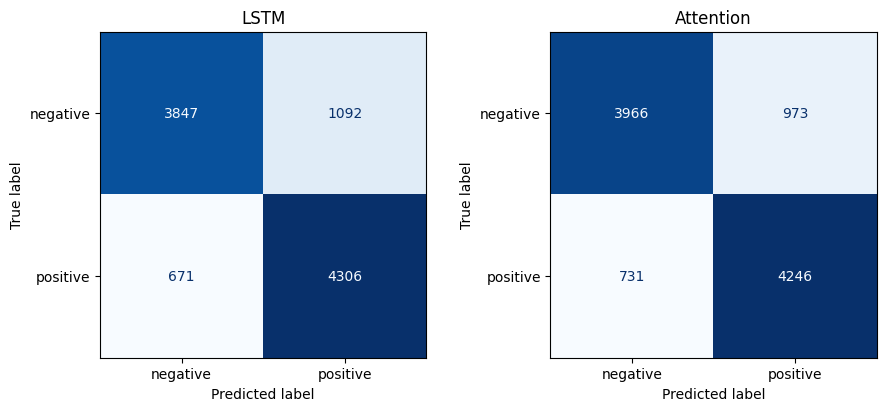

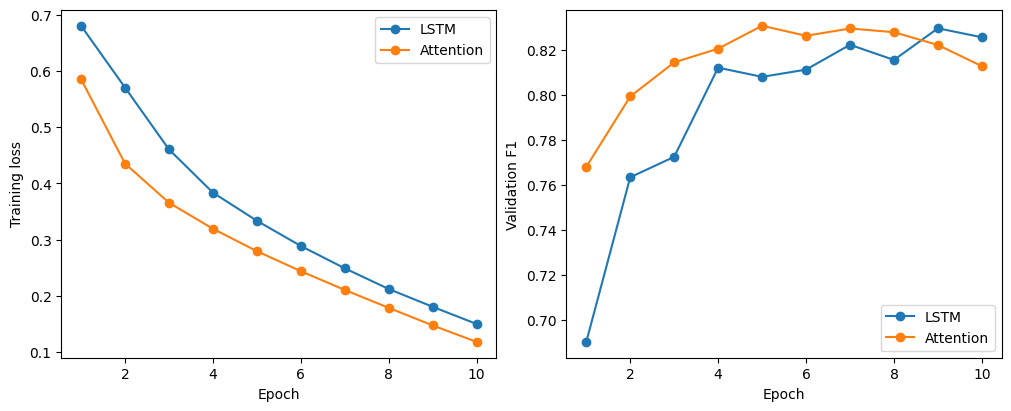

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, (name, evaluation) in zip(axes, evaluations.items()):
    matrix = confusion_matrix(evaluation["labels"], evaluation["predictions"], labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["negative", "positive"]).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(name)
fig.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for name, history in histories.items():
    frame = pd.DataFrame(history)
    axes[0].plot(frame["Epoch"], frame["Train loss"], marker="o", label=name)
    axes[1].plot(frame["Epoch"], frame["Validation F1"], marker="o", label=name)
axes[0].set(xlabel="Epoch", ylabel="Training loss")
axes[1].set(xlabel="Epoch", ylabel="Validation F1")
for ax in axes:
    ax.legend()
fig.savefig(OUTPUT_DIR / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()

Đối chiếu confusion matrix và diễn biến huấn luyện

Confusion matrix dùng hàng là nhãn thật và cột là nhãn dự đoán. LSTM phân loại đúng 3.847 review negative và 4.306 review positive; nhầm 1.092 negative thành positive và 671 positive thành negative. Tổng đúng là 8.153/9.916, khớp Accuracy 82,22%.

Attention phân loại đúng 3.966 negative và 4.246 positive; nhầm 973 negative thành positive và 731 positive thành negative. Tổng đúng là 8.212/9.916, khớp Accuracy 82,82%. So với LSTM, Attention giảm 119 lỗi negative thành positive nhưng tăng 60 lỗi positive thành negative; số dự đoán đúng toàn tập tăng 59. Do đó cải thiện accuracy không đồng nghĩa cải thiện ở cả hai lớp.

F1 được tính cho positive. Từ matrix Attention, precision positive = 4.246/(4.246 + 973), recall positive = 4.246/(4.246 + 731), cho F1 xấp xỉ 0,832876, nhất quán với results.csv. Matrix LSTM cũng cho F1 khoảng 0,830072.

LSTM giảm train loss từ 0,680581 ở epoch 1 xuống 0,149805 ở epoch 10. Validation loss thấp nhất khoảng 0,415191 ở epoch 6, sau đó lên 0,516376 ở epoch 10. Validation F1 cao nhất ở epoch 9 là 0,829439, rồi giảm còn 0,825443; vì chọn theo F1 nên checkpoint epoch 9 được dùng.

Attention giảm train loss từ 0,585415 xuống 0,117962. Validation loss thấp nhất ở epoch 4 là 0,392372, nhưng tăng lên 0,668985 ở epoch 10; validation F1 cao nhất ở epoch 5 là 0,830565 rồi giảm còn 0,812595 ở epoch 10. Diễn biến train loss tiếp tục giảm trong khi validation xấu đi cho thấy dấu hiệu overfitting. Lưu checkpoint theo validation F1 giúp tránh dùng mặc định epoch cuối, nhưng không loại bỏ hoàn toàn hạn chế tổng quát hóa.

25 and 29. Sequence length and computational cost

In [37]:
sequence_lengths = np.array([10, 100, 500, 1000, 10_000], dtype=np.int64)
matrix_elements = sequence_lengths ** 2
experiment5_table = pd.DataFrame({
    "Sequence length (T)": sequence_lengths,
    "Attention matrix": [f"{length} x {length}" for length in sequence_lengths],
    "Elements (T^2)": matrix_elements,
    "Growth vs T=10": matrix_elements // matrix_elements[0],
    # One materialized matrix, one sample, one head. Not total training memory.
    "One float32 matrix (MiB)": matrix_elements * np.dtype(np.float32).itemsize / 1024 ** 2,
})
display(experiment5_table)
experiment5_table.to_csv(OUTPUT_DIR / "sequence_length_cost.csv", index=False)

,Sequence length (T),Attention matrix,Elements (T^2),Growth vs T=10,One float32 matrix (MiB)
0,10,10 x 10,100,1,0.000381
1,100,100 x 100,10000,100,0.038147
2,500,500 x 500,250000,2500,0.953674
3,1000,1000 x 1000,1000000,10000,3.814697
4,10000,10000 x 10000,100000000,1000000,381.469727


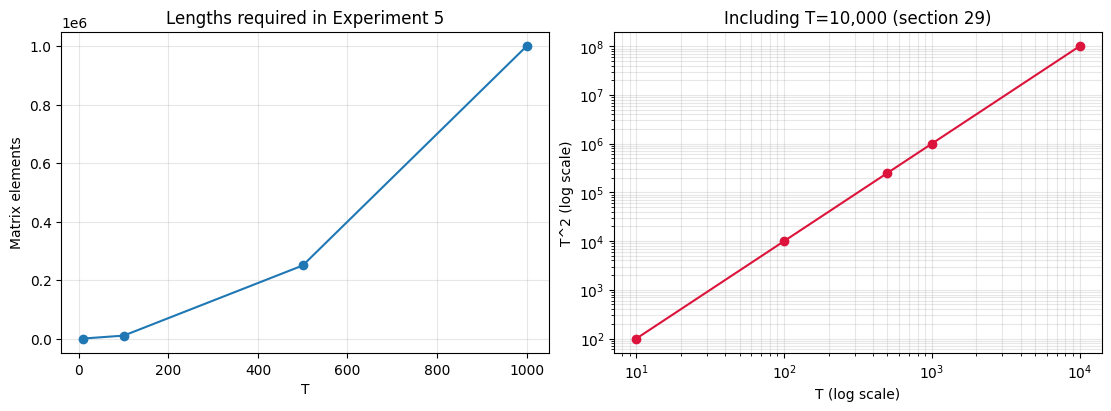

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(sequence_lengths[:4], matrix_elements[:4], marker="o")
axes[0].set(title="Lengths required in Experiment 5", xlabel="T", ylabel="Matrix elements")
axes[1].loglog(sequence_lengths, matrix_elements, marker="o", color="crimson")
axes[1].set(title="Including T=10,000 (section 29)", xlabel="T (log scale)", ylabel="T^2 (log scale)")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
fig.savefig(OUTPUT_DIR / "sequence_length_cost.png", dpi=160, bbox_inches="tight")
plt.show()

Nhận xét Experiment 5 và trả lời: vì sao self-attention tốn chi phí khi sequence dài?

Theo bảng, T = 10 tạo 100 phần tử; T = 100 tạo 10.000; T = 500 tạo 250.000; T = 1.000 tạo 1.000.000. So với T = 10, các mức tương ứng tăng 1, 100, 2.500 và 10.000 lần. Vì vậy tăng độ dài từ 10 lên 1.000 là tăng T 100 lần nhưng tăng số cặp query-key 10.000 lần. Nếu T tăng gấp đôi, số phần tử tăng gấp bốn.

Một ma trận float32 của một mẫu, một head cần khoảng 0,000381 MiB ở T = 10; 0,038147 MiB ở T = 100; 0,953674 MiB ở T = 500; 3,814697 MiB ở T = 1.000. Dòng mở rộng ở mục 29 cho T = 10.000 có 100.000.000 phần tử và cần khoảng 381,47 MiB cho riêng một ma trận, gấp 100 lần mức T = 1.000. Code chỉ tính kích thước dự kiến, không thực sự cấp phát ma trận 10.000 x 10.000.

Full self-attention phải tính tương tác giữa mỗi query và mọi key. Tính QK.T có chi phí theo T² x d_k, còn A @ V theo T² x d_v; nếu giữ cố định d_k và d_v thì chi phí phần attention tăng theo O(T²). Với cách triển khai lưu ma trận đầy đủ trong notebook, bộ nhớ scores/weights cũng tăng theo T².

Trong classifier đang dùng, batch size là 128. Chỉ một ma trận float32 cho cả batch cần khoảng 4,88 MiB ở T = 100 nhưng khoảng 488,28 MiB ở T = 1.000. Training còn cần scores, weights, Q/K/V, các activation và gradient, nên đây chưa phải tổng bộ nhớ model. Việc Attention chạy nhanh hơn LSTM ở max length 100 không phủ nhận hạn chế tăng chi phí khi sequence rất dài.

26. Application - Context-aware sentiment

In [39]:
attention_model = trained_models["Attention"]


@torch.inference_mode()
def predict_with_attention(text):
    attention_model.eval()
    raw_tokens = tokenize(text)
    tokens = raw_tokens[:EXP4_MAX_LENGTH] or ["<unk>"]
    token_ids = [vocab.get(token, UNK_ID) for token in tokens]
    input_ids, lengths, _ = collate_batch([(token_ids, 0)])
    context, weights = attention_model.representation(
        input_ids.to(DEVICE), lengths, return_weights=True
    )
    probabilities = attention_model.classifier(context).softmax(dim=-1)[0].cpu().numpy()
    predicted_id = int(probabilities.argmax())
    matrix = weights[0, :len(tokens), :len(tokens)].cpu().numpy()
    # Mean attention received, consistent with the model's mean context pooling.
    # This distribution is not a causal explanation of the prediction.
    token_attention = matrix.mean(axis=0)
    np.testing.assert_allclose(token_attention.sum(), 1.0, atol=1e-6)
    return {
        "text": text, "tokens": tokens, "prediction": ID_TO_LABEL[predicted_id],
        "probabilities": probabilities, "confidence": float(probabilities[predicted_id]),
        "attention_matrix": matrix, "token_attention": token_attention,
        "original_tokens": len(raw_tokens), "truncated": len(raw_tokens) > EXP4_MAX_LENGTH,
        "unknown_tokens": token_ids.count(UNK_ID),
    }


application_examples = [
    ("I like this movie.", "positive"),
    ("I do not like this movie.", "negative"),
    ("I thought this movie would be bad, but it was actually excellent.", "positive"),
]
application_outputs = [predict_with_attention(text) for text, _ in application_examples]
application_results = pd.DataFrame([
    {
        "Text": result["text"], "Reference label": reference,
        "Prediction": result["prediction"], "Correct": result["prediction"] == reference,
        "P(negative)": result["probabilities"][LABEL_TO_ID["negative"]],
        "P(positive)": result["probabilities"][LABEL_TO_ID["positive"]],
        "Confidence": result["confidence"], "Unknown tokens": result["unknown_tokens"],
    }
    for result, (_, reference) in zip(application_outputs, application_examples)
])
display(application_results.round(4))
application_results.to_csv(OUTPUT_DIR / "context_aware_sentiment_predictions.csv", index=False)

,Text,Reference label,Prediction,Correct,P(negative),P(positive),Confidence,Unknown tokens
0,I like this movie.,positive,negative,False,0.9402,0.0598,0.9402,0
1,I do not like this movie.,negative,negative,True,0.9948,0.0052,0.9948,0
2,"I thought this movie would be bad, but it was ...",positive,negative,False,0.6308,0.3692,0.6308,0


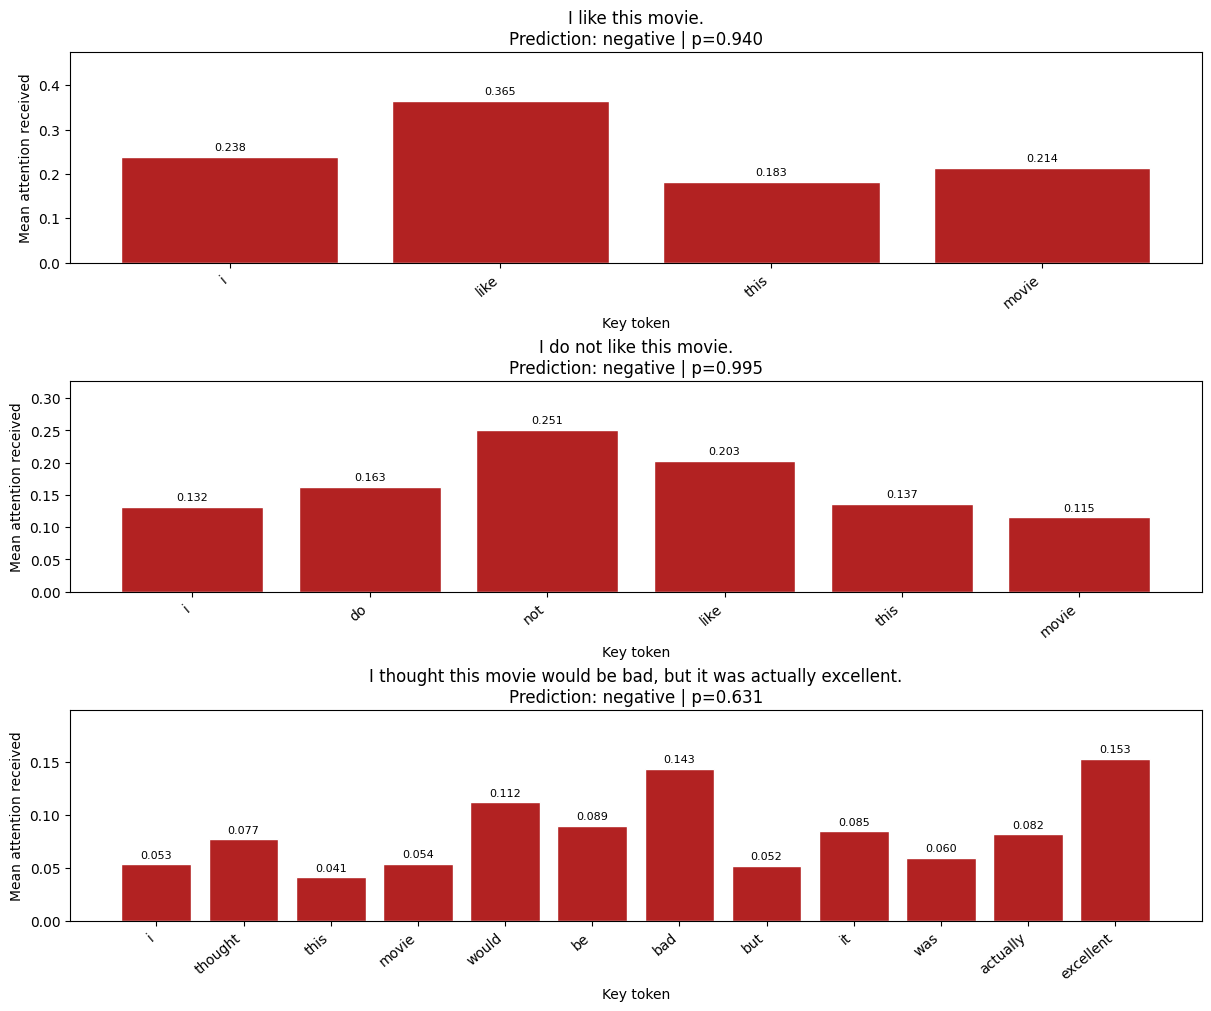

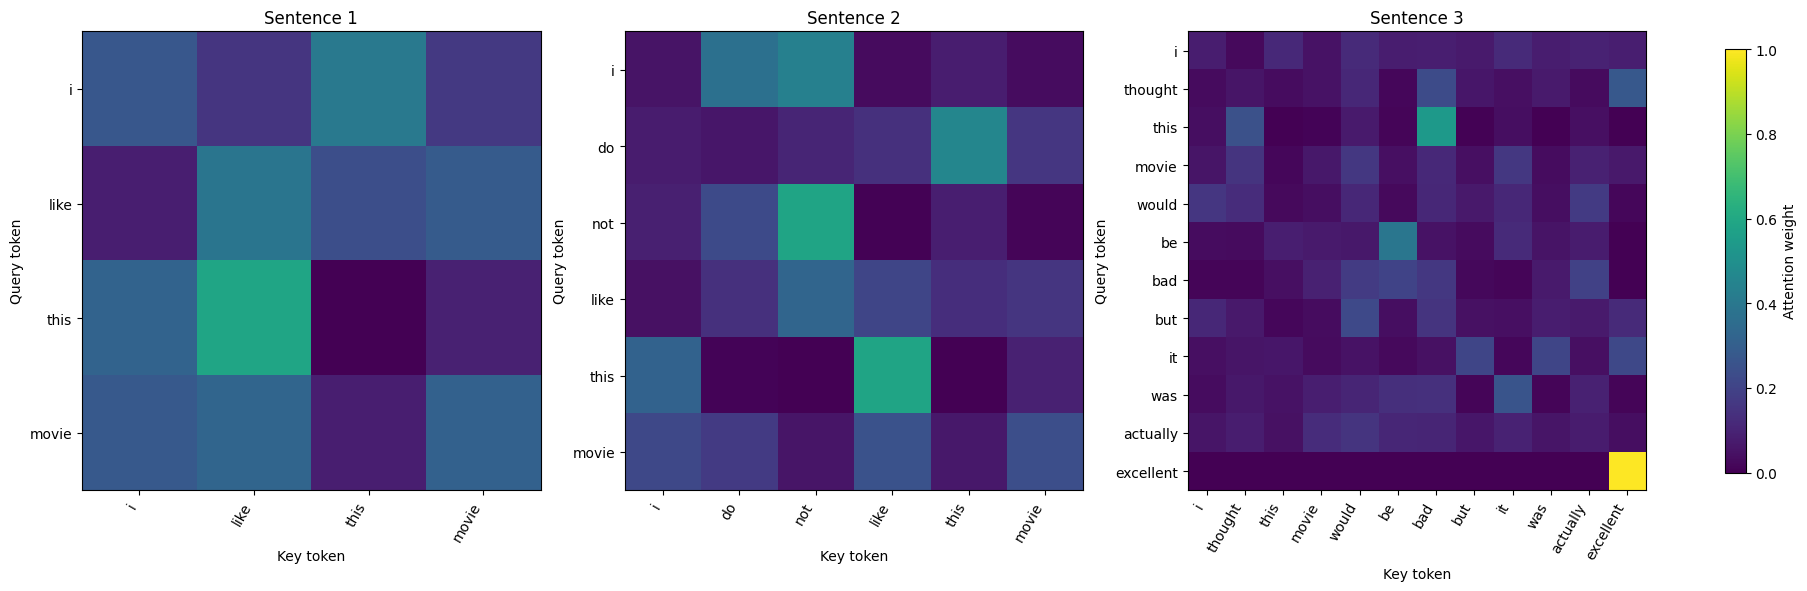

In [40]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), constrained_layout=True)
for ax, result in zip(axes, application_outputs):
    plot_token_attention(
        ax, result["tokens"], result["token_attention"],
        f"{result['text']}\nPrediction: {result['prediction']} | p={result['confidence']:.3f}",
        color="seagreen" if result["prediction"] == "positive" else "firebrick",
    )
    ax.set_ylabel("Mean attention received")
fig.savefig(OUTPUT_DIR / "context_aware_sentiment_attention.png", dpi=160, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for index, (ax, result) in enumerate(zip(axes, application_outputs), start=1):
    image = ax.imshow(result["attention_matrix"], cmap="viridis", vmin=0, vmax=1)
    positions = np.arange(len(result["tokens"]))
    ax.set_xticks(positions, labels=result["tokens"], rotation=60, ha="right")
    ax.set_yticks(positions, labels=result["tokens"])
    ax.set(title=f"Sentence {index}", xlabel="Key token", ylabel="Query token")
fig.colorbar(image, ax=axes, label="Attention weight", shrink=0.8)
fig.savefig(OUTPUT_DIR / "application_attention_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

Nhận xét Application: prediction, probability và attention của ba câu

Cả ba câu đều ngắn hơn 100 token và có Unknown tokens = 0. Do đó lỗi trong các câu này không thể quy trực tiếp cho việc bị cắt ở giới hạn 100 hoặc token bị đổi thành UNK. Hai lớp được đánh giá bằng xác suất softmax; xác suất cao không bảo đảm prediction đúng.

1. "I like this movie."

Nhãn tham chiếu positive nhưng model dự đoán negative: P(negative) = 0,940191 và P(positive) = 0,059809. Đây là prediction sai với độ tự tin cao. Mean attention received của "like" cao nhất, khoảng 0,364625; tiếp theo "i" 0,238457, "movie" 0,214417 và "this" 0,182500. Như vậy token mang tín hiệu tích cực rõ vẫn nhận weight cao nhất mà câu bị phân loại sai. Không thể giải thích lỗi đơn giản bằng việc attention bỏ qua "like". Giả thuyết cần xét là biểu diễn value/classifier chưa tổng quát hóa tốt cho câu ngắn này; kết quả hiện tại chưa xác định nguyên nhân nhân quả.

2. "I do not like this movie."

Nhãn tham chiếu và prediction đều negative: P(negative) = 0,994752 và P(positive) = 0,005248. "not" có attention cao nhất 0,250777, "like" đứng tiếp theo 0,202992 và "do" khoảng 0,162647. Khi thêm "do not", P(negative) tăng từ 0,940191 lên 0,994752, khoảng 5,46 điểm phần trăm. Đây là thay đổi hành vi phù hợp với tín hiệu phủ định trong cặp câu, nhưng vì câu khẳng định ban đầu đã bị dự đoán negative, cặp này chưa chứng minh model phân biệt thành công sentiment của khẳng định và phủ định.

3. "I thought this movie would be bad, but it was actually excellent."

Nhãn tham chiếu positive nhưng prediction là negative: P(negative) = 0,630799 và P(positive) = 0,369201. "excellent" nhận attention cao nhất 0,152759, nhỉnh hơn "bad" 0,143467; "would" khoảng 0,111834, còn "but" chỉ khoảng 0,051692. Vì "excellent" đã đứng đầu, không có cơ sở nói model sai do chỉ nhìn vào "bad" hoặc không nhìn thấy từ tích cực. Giả thuyết hợp lý hơn là sự kết hợp value, mean pooling và classifier chưa xử lý tốt quan hệ đổi ý, cùng giới hạn thiếu thông tin thứ tự của kiến trúc hiện tại. Đây là giả thuyết dựa trên output, chưa phải kết quả của thử nghiệm can thiệp.

Nhìn chung chỉ 1/3 câu Application được dự đoán đúng. Đây là bộ câu kiểm tra nhỏ, không thay thế Accuracy 82,82% trên 9.916 mẫu test. Nó cho thấy kết quả tổng thể khá tốt vẫn có thể đi kèm lỗi rõ ràng ở câu khẳng định ngắn hoặc câu có chuyển hướng cảm xúc.

Cách đọc biểu đồ: ma trận A cho biết từng query phân phối weight tới các key; biểu đồ cột lấy trung bình các hàng A trên những query hợp lệ. Do classifier dùng mean pooling token context, phân phối này phù hợp với phép tổng hợp context. Tuy nhiên prediction còn phụ thuộc value vectors và trọng số classifier; weight cao không đồng nghĩa đóng góp tích cực, cũng không phải thước đo nhân quả của tầm quan trọng. Hai ví dụ sai phía trên minh họa trực tiếp giới hạn đó. Câu 2 được chọn làm ca đúng, câu 1 và câu 3 là ca sai để phân tích ở phần Application.

27. Error analysis - mẫu đúng, mẫu sai và giả thuyết

Correct cases selected: 3/3
Incorrect cases selected: 3/3


,sample_id,label,prediction,correct,confidence,truncated
0,8149,negative,negative,True,0.976989,True
1,13719,negative,negative,True,0.865894,True
2,3484,positive,positive,True,0.969610,False
3,39028,negative,positive,False,0.857688,True
4,23000,negative,positive,False,0.993381,True
5,13358,positive,negative,False,0.825863,True


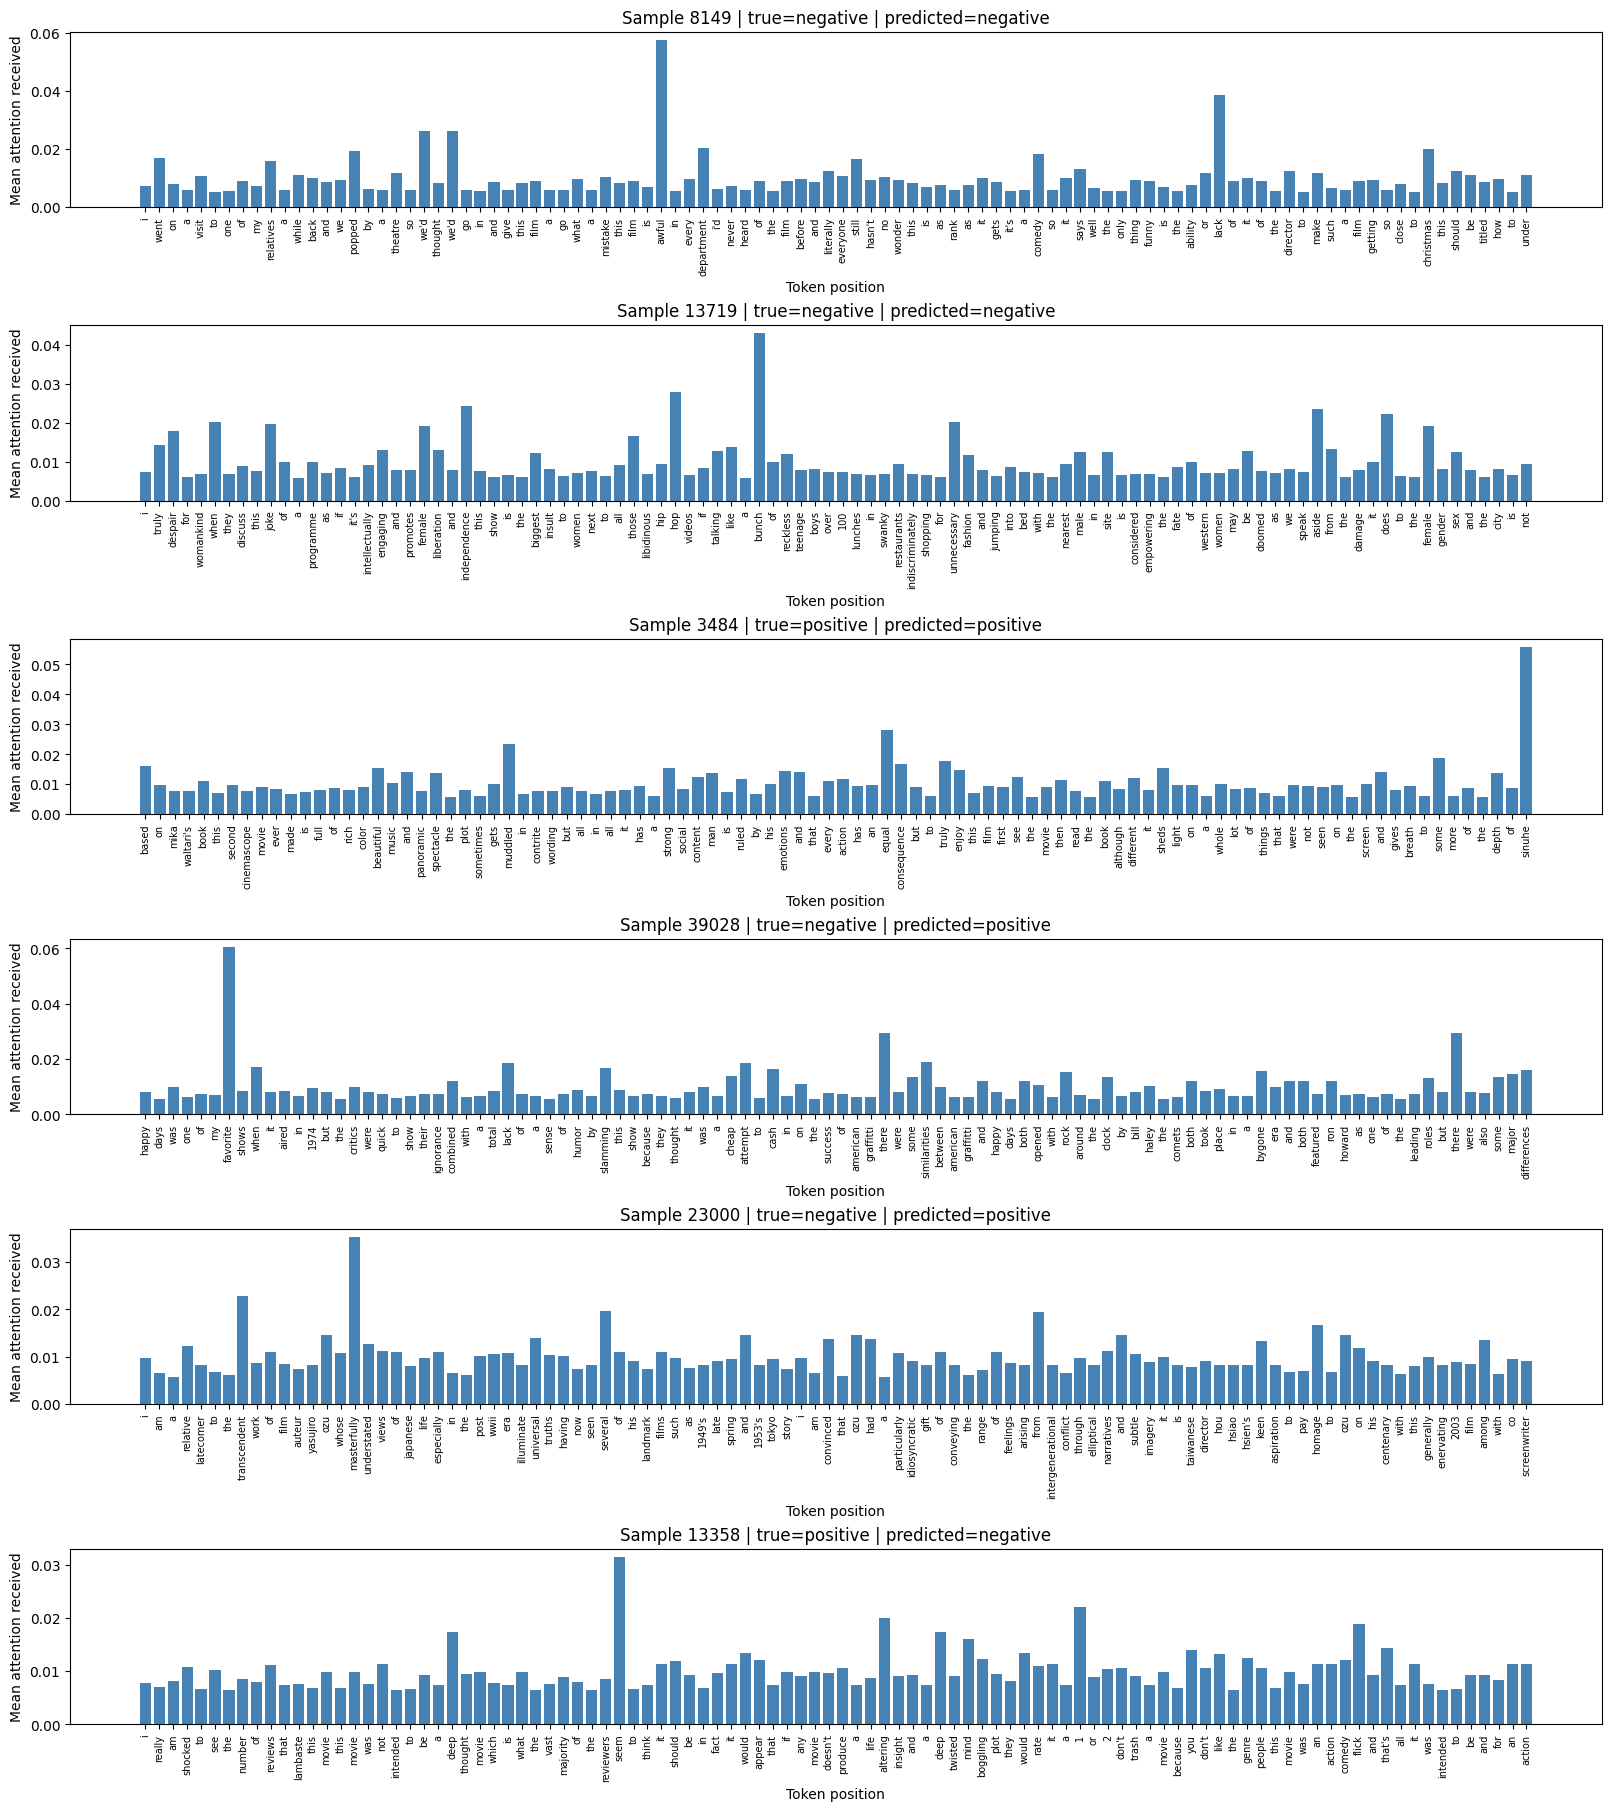

In [41]:
test_evaluation = evaluations["Attention"]
test_predictions = test_df[["sample_id", "text_clean", "label", "token_count"]].copy()
test_predictions["prediction"] = [ID_TO_LABEL[int(value)] for value in test_evaluation["predictions"]]
test_predictions["confidence"] = test_evaluation["probabilities"].max(axis=1)
test_predictions["P(negative)"] = test_evaluation["probabilities"][:, LABEL_TO_ID["negative"]]
test_predictions["P(positive)"] = test_evaluation["probabilities"][:, LABEL_TO_ID["positive"]]
test_predictions["correct"] = test_predictions["prediction"].eq(test_predictions["label"])
test_predictions["truncated"] = test_predictions["token_count"] > EXP4_MAX_LENGTH
test_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

# Select real held-out cases. Never create a wrong prediction artificially.
case_groups = []
for is_correct in (True, False):
    candidates = test_predictions[test_predictions["correct"].eq(is_correct)]
    selected = candidates.sample(n=min(3, len(candidates)), random_state=RANDOM_SEED)
    case_groups.append(selected)
    print(f"{'Correct' if is_correct else 'Incorrect'} cases selected: {len(selected)}/3")
analysis_cases = pd.concat(case_groups, ignore_index=True)
analysis_outputs = [predict_with_attention(text) for text in analysis_cases["text_clean"]]
analysis_cases["unknown_tokens"] = [result["unknown_tokens"] for result in analysis_outputs]
analysis_cases["top_attended_tokens"] = [
    "; ".join(
        f"{result['tokens'][index]} ({result['token_attention'][index]:.4f})"
        for index in np.argsort(-result["token_attention"], kind="stable")[:5]
    )
    for result in analysis_outputs
]
# These fields are for manual analysis after inspecting the outputs.
for column in ("error_category", "hypothesis", "evidence"):
    analysis_cases[column] = ""
analysis_cases.to_csv(OUTPUT_DIR / "error_analysis_cases.csv", index=False)
display(analysis_cases[["sample_id", "label", "prediction", "correct", "confidence", "truncated"]])

if analysis_outputs:
    fig, axes = plt.subplots(
        len(analysis_outputs), 1, figsize=(16, 3 * len(analysis_outputs)),
        squeeze=False, constrained_layout=True,
    )
    for ax, row, result in zip(axes.flat, analysis_cases.to_dict("records"), analysis_outputs):
        positions = np.arange(len(result["tokens"]))
        ax.bar(positions, result["token_attention"], color="steelblue")
        ax.set_xticks(positions, labels=result["tokens"], rotation=90, fontsize=7)
        ax.set(
            title=f"Sample {row['sample_id']} | true={row['label']} | predicted={row['prediction']}",
            ylabel="Mean attention received", xlabel="Token position",
        )
    fig.savefig(OUTPUT_DIR / "error_analysis_attention.png", dpi=160, bbox_inches="tight")
    plt.show()

27. Error analysis trên 3 correct và 3 incorrect từ tập test

Sáu sample_id phía dưới là các mẫu thực được chọn trong error_analysis_cases.csv, không phải dữ liệu tạo để có lỗi. "Attention cao nhất" ở phần này là mean attention received trên các token đã được giữ. Với review dài hơn 100 token, model không nhận phần sau dù nhãn tham chiếu đánh giá toàn bộ review. Với ca đúng, các nhóm như truncation/rare word được ghi như yếu tố cần khảo sát chứ không gọi là lỗi phân loại đã xảy ra.

Ca đúng 1 - sample_id 8149

Nhãn thật negative, prediction negative; P(negative) = 0,976989. Review có 242 token nhưng chỉ giữ 100, không có token UNK trong phần đầu vào. Người viết nói "What a mistake! This film is awful in every department"; "awful" ở vị trí 38 và "lack" ở vị trí 78 đều nằm trong đoạn được giữ. Attention cao nhất là "awful" 0,057618, sau đó "lack" 0,038825. Hai từ này phù hợp với tín hiệu phê bình mà người đọc dự kiến là quan trọng. Dù có truncation, model vẫn dự đoán đúng trên ca này; chưa thể từ một ca kết luận cắt 100 token là đủ cho mọi review.

Ca đúng 2 - sample_id 13719

Nhãn thật negative, prediction negative; P(negative) = 0,865894. Review có 307 token, bị cắt còn 100, trong đó có 6 token ngoài vocabulary. Các yếu tố cần xem xét là negation, truncation và rare word. Cụm "NOT ENTERTAINING" bị cắt giữa chừng: "not" là token 100 và "entertaining" là token 101. Top attention là "bunch" 0,042915, "hop" 0,027941 và "independence" 0,024388; các từ này không trực tiếp trùng với tín hiệu cảm xúc rõ nhất mà người đọc thường chọn như "despair", "insult" hoặc "doomed". Prediction vẫn đúng, nên ca này cho thấy pattern không trùng trực giác không đồng nghĩa model sai. Cũng không thể dùng kết quả này để chứng minh model hiểu trọn phủ định "not entertaining", vì một nửa cụm đã nằm ngoài đầu vào.

Ca đúng 3 - sample_id 3484

Nhãn thật positive, prediction positive; P(positive) = 0,969610. Review chỉ có 96 token nên không bị cắt, nhưng có 5 token ngoài vocabulary: "mika", "waltari's", "panoramic", "contrite", "wording". Đoạn review đan xen lời khen "rich color", "beautiful music", "strong social content" với từ chê "muddled", nên cần xem xét ambiguous wording và rare word. Attention cao nhất là "sinuhe" 0,055808, sau đó "equal" 0,028101 và "muddled" 0,023343. Các từ khen rõ không đứng đầu, nhưng model vẫn dự đoán positive. "Sinuhe" thực tế có trong vocabulary của checkpoint này; không nên suy ra nó là UNK chỉ vì là tên riêng. Pattern này chưa giải thích được đầy đủ vì sao classifier chọn positive.

Ca sai 1 - sample_id 39028

Nhãn thật negative nhưng prediction positive; P(positive) = 0,857688. Review có 651 token, bị cắt còn 100 và có 3 token ngoài vocabulary trong phần giữ lại. Nhóm lỗi được đề xuất là truncation, kèm ambiguous wording do lời khen ban đầu khác đánh giá cuối. Phần đầu nói "one of my favorite shows", còn cuối review phê bình bản DVD thay nhạc gốc và làm mất sự hấp dẫn của chương trình. "favorite" ở vị trí 7 nhận attention cao nhất 0,060445. Người đọc toàn bài có thể chọn phần phê bình DVD cuối làm tín hiệu nhãn, nhưng model không nhận đoạn đó. Giả thuyết là đầu vào bị giới hạn khiến model thiên về cảm xúc tích cực ban đầu; attention vào "favorite" phù hợp với giả thuyết nhưng không tự chứng minh nguyên nhân. Cần tăng hoặc thay cửa sổ token, sau đó đối chiếu prediction/xác suất để kiểm chứng.

Ca sai 2 - sample_id 23000

Nhãn thật negative nhưng prediction positive; P(positive) = 0,993381. Review dài 496 token, chỉ giữ 100 và có 14 token ngoài vocabulary. Nhóm lỗi được đề xuất là truncation, long-range dependency và rare word. Đầu bài khen phong cách của Ozu, sau đó chuyển sang chê bộ phim của Hou Hsiao-hsien. "masterfully" ở token 16 nhận 0,035292, "transcendent" ở token 8 nhận 0,022863 và "homage" nhận 0,016657. Ngay trong 100 token đầu cũng có "enervating" ở vị trí 94, nhưng từ này nằm ngoài vocabulary nên bị đổi thành UNK. Vì vậy không đúng nếu nói model chỉ nhận toàn lời khen hoặc mọi dấu hiệu tiêu cực đều bị cắt. Giả thuyết là kết hợp mất phần phê bình dài phía sau, mất biểu diễn riêng của từ chê hiếm và chưa gắn đúng đối tượng được khen/chê. Xác suất sai 99,34% cho thấy model tự tin sai, không phải bằng chứng nó hiểu nội dung. Cần kiểm tra riêng thay đổi cửa sổ và biểu diễn từ hiếm để phân biệt các giả thuyết.

Ca sai 3 - sample_id 13358

Nhãn thật positive nhưng prediction negative; P(negative) = 0,825863. Review có 321 token, bị cắt còn 100, có 1 token ngoài vocabulary là "lambaste". Nhóm lỗi được đề xuất là negation, ambiguous wording và truncation. Đầu bài nhắc lại lời chê của người khác và phản bác kỳ vọng rằng phim phải có cốt truyện sâu sắc; quan điểm khen rõ như "well done" ở token 105-106 và "enjoyed" ở token 114 bị loại khỏi đầu vào. Top attention là "seem" 0,031539, "1" 0,022060, "altering" 0,020012; các token này chưa phản ánh rõ lời khen mà người đọc toàn bài dự kiến là quan trọng. Giả thuyết là model chưa phân biệt tốt lời chê được thuật lại với đánh giá thật, đồng thời thiếu đoạn kết luận tích cực do truncation. Cần đối chiếu khi giữ đoạn sau hoặc cung cấp toàn bộ thông tin cần thiết để kiểm chứng; chưa thể kết luận attention vào các từ trên gây ra lỗi.

Tổng hợp và giới hạn của phần phân tích

Cả ba ca sai được chọn đều bị truncation, nhưng hai trong ba ca đúng cũng bị truncation. Điều này khiến truncation là giả thuyết đáng kiểm tra, chưa đủ để kết luận nó là nguyên nhân duy nhất. Sáu ca chỉ là mẫu phân tích định tính, không đại diện cho mọi lỗi trong tập test.

Các bằng chứng hiện có phù hợp để đề xuất các nhóm negation, long-range dependency, ambiguous wording, rare word và truncation. Chưa có bằng chứng đủ rõ trong sáu ca để gán sarcasm hoặc noise. Cũng chưa có kiểm tra chuyển miền độc lập để khẳng định domain shift, nên không ép mỗi nhóm lỗi phải xuất hiện.

Về câu hỏi attention có tập trung vào token người đọc dự đoán quan trọng không: ca 8149 có sự trùng khớp rõ với "awful"; ca 13719 và 3484 dự đoán đúng dù top attention không trùng trực tiếp các từ cảm xúc nổi bật. Ở ca 39028 và 23000, attention cao trên tín hiệu khen đầu bài phù hợp với prediction positive sai; ở ca 13358, các cụm khen quan trọng đã bị cắt. Các quan sát này hỗ trợ việc xây dựng giả thuyết, không cho phép kết luận "attention nhìn sai từ nên model sai".

Những kiểm chứng như thay cửa sổ giữ token, tăng max length, thay từ hiếm bằng từ đồng nghĩa có trong vocabulary hoặc kiểm tra câu khẳng định/phủ định cần được chạy thành thí nghiệm riêng. Tại đây chưa có output can thiệp đó; phần phân tích không coi các giả thuyết là đã được xác nhận.

28. Trả lời câu hỏi so sánh LAB 05 và LAB 06

Attention giải quyết vấn đề gì của recurrent processing?

LSTM trong thí nghiệm nén chuỗi vào final hidden state; thông tin của token đầu phải đi qua các lần cập nhật recurrent để ảnh hưởng trạng thái cuối. Self-attention tạo đường tương tác trực tiếp giữa mỗi cặp token đã có trong đầu vào, rồi tổng hợp value theo query. Ví dụ ở toy self-attention, query "cat" nhận weight 0,184528 từ "sleeping" dù hai token không liền nhau. Điều này minh họa khả năng kết hợp thông tin không cần chuỗi cập nhật recurrent giữa hai vị trí, chưa chứng minh model học được một quan hệ ngữ pháp cụ thể.

Các phép nhân ma trận của Attention có thể thực hiện song song theo vị trí, trong khi LSTM phụ thuộc hidden state ở bước trước. Trên CPU và cấu hình hiện tại, thời gian training là 185,79 giây so với 1.420,42 giây. Kết quả này phù hợp với lợi thế xử lý của triển khai hiện tại; nó không phải phép đo tách biệt hoàn toàn ảnh hưởng kiến trúc, số tham số và tối ưu thư viện.

Attention tạo ra vấn đề mới nào?

Thứ nhất, full attention lưu và xử lý T² tương tác: bảng cho thấy từ T = 1.000 lên 10.000, một ma trận tăng từ 1 triệu lên 100 triệu phần tử. Thứ hai, self-attention thuần không tự đưa thứ tự token vào biểu diễn. Classifier Attention hiện tại chỉ có embedding, Q/K/V và mean pooling, nên khác LSTM ở chỗ không mã hóa thứ tự một cách tường minh. Đây là hạn chế cần nhớ khi xem câu có "not" hoặc "but"; chưa thể suy ra quan hệ đổi ý chỉ từ một ô attention lớn.

Thứ ba, attention chỉ kết hợp những token còn trong đầu vào. Nó không khôi phục các đoạn đã mất do max length 100: chẳng hạn "well done" và "enjoyed" trong sample 13358 nằm ngoài đoạn được giữ. Thứ tư, attention visualization chỉ mô tả weights, không tự xác nhận reasoning; câu Application thứ ba có "excellent" nhận weight cao nhất vẫn bị dự đoán negative. Do đó không có cơ sở từ lần chạy này để nói Attention luôn thay thế hoặc luôn tốt hơn RNN.

31. Trả lời các câu hỏi kiến thức còn lại từ thực nghiệm

1. Attention score được tính như thế nào?

Dot-product score giữa query q_i và key k_j là tích vô hướng của hai vector. Với scaled dot-product attention, chia thêm cho sqrt(d_k). Trong Experiment 1, dot product với key "good" là 2 và d_k = 4 nên scaled score của "good" là 1; weight sau softmax là 0,234427.

2. Tại sao dùng softmax?

Softmax chuyển scores thành các weight dương, tổng bằng 1 cho mỗi query, giữ thứ tự ưu tiên theo score. Trong Experiment 1, score của "slow" là -0,5 nhưng weight vẫn là 0,052308; không thể dùng trực tiếp score âm như một xác suất. Softmax cũng cho phép nhiều value cùng tham gia thay vì chỉ chọn cứng một token.

3. Query, Key, Value có vai trò gì?

Query biểu diễn thông tin đang tìm; key được so khớp với query để tạo scores; value là thông tin được phối trộn để tạo context. Experiment 2 giữ nguyên K/V nhưng thay Q làm token đứng đầu đổi từ "good" sang "movie", trực tiếp thể hiện vai trò truy vấn. Toy self-attention cho thấy V có thể khác K dù cùng được tạo từ X.

4. Context vector được tính như thế nào?

Lấy tổng các value với hệ số là attention weights, dạng ma trận C = A @ V. Ví dụ query "I" trong NumPy self-attention kết hợp ba value [1, 1], [1, -1], [2, 0] và tạo context khoảng [1,4555; -0,0953]. Trong classifier, các token context còn được mean pooling trên vị trí hợp lệ để lấy representation của cả review.

5. Tại sao chia cho sqrt(d_k)?

Phép chia kiểm soát độ lớn của dot product khi chiều vector tăng, hạn chế softmax quá tập trung do scores lớn. Với d_k = 4 trong bảng scaling, max weight giảm từ 0,866813 xuống 0,665241. Nó không làm đảo thứ tự scores.

6. Self-attention khác attention thông thường ở đâu?

Ở attention tổng quát, query và key/value có thể đến từ các nguồn khác nhau. Trong self-attention, Q/K/V được tạo từ cùng sequence X qua các phép chiếu. NumPy demo có ba token tạo ba query, nên trả về ma trận 3 x 3; Experiment 1 dùng một query giả lập cho mười token nên trả về một hàng 1 x 10.

7. Nếu sequence dài gấp đôi, attention matrix thay đổi thế nào?

T x T trở thành 2T x 2T, tức số phần tử tăng bốn lần. Điều này áp dụng cho full self-attention ở đây; chiều representation 64 không tự giảm chi phí tương tác T².

8. Attention có chứng minh model đang reasoning không?

Không. Câu "I like this movie" có "like" nhận mean attention lớn nhất 0,364625 nhưng vẫn bị phân loại negative với xác suất 0,940191. Câu có "excellent" cũng sai dù từ đó đứng đầu attention. Hai output này cho thấy nhìn vào weights không đủ để giải thích prediction hay suy ra reasoning.

9. Tại sao attention có thể xử lý long-range interaction thuận tiện hơn recurrent state?

Một query có thể kết hợp trực tiếp với key/value ở vị trí xa trong cùng đầu vào, thay vì chờ thông tin đi qua các bước recurrent trung gian. Tuy nhiên khả năng tương tác này không bảo đảm sẽ học đúng quan hệ cần thiết và không vượt qua giới hạn truncation. Các sample sai 39028, 23000, 13358 đều thiếu phần review sau token 100.

10. Bài thực nghiệm này đã cho thấy những giới hạn nào?

Accuracy của Attention là 82,82% chứ không phải hoàn hảo; ba câu Application chỉ đúng một câu. Validation loss của Attention tăng lên 0,668985 ở epoch 10 dù train loss giảm còn 0,117962. Ma trận ở T = 10.000 cần 100 triệu phần tử, và 87,37% review test bị cắt ở giới hạn hiện tại. Đây là các bằng chứng cụ thể về lỗi tổng quát hóa, overfitting và chi phí/giới hạn độ dài; chưa phải bằng chứng attention luôn kém hoặc luôn hơn LSTM.